# 📖 Türk Bilimkurgu Yazar-Çevirmenleri Derlem Analizi
### Temelden İleriye, Akademik ve Bellek Korumalı Derlembilim Not Defteri

**Kapsam ve Bağlam.** Bu not defteri, modern Türk bilimkurgu edebiyatının öncü kuşağını
temsil eden **üç öncü yazar-çevirmenin** yapıtlarını incelemektedir:
**Selma Mine**, **Zühtü Bayar** ve **Özlem Kurdoğlu** — toplamda **13 metin**:
- **5 İngilizce Kaynak Metin**: Asimov (*I, Robot*), Anderson (*The Light*), Leinster (*The Lonely Planet*), London (*The Scarlet Plague*), Dick (*A Scanner Darkly*);
- **5 Türkçe Çeviri**: *Ben, Robot* (Mine 1983), *Aydınlık* (Bayar 1998), *Yalnız Gezegen* (Bayar 1998), *Kıyametten Sonra* (Bayar 1998), *Karanlığı Taramak* (Kurdoğlu 1998);
- **3 Özgün Yerli Türkçe Bilimkurgu Romanı**: *OBİ,J.S.927* (Mine 1980), *Sahte Uygarlık* (Bayar 1999), *Son Cephede Şafak* (Kurdoğlu 2000).

Bu 13 metin, doktora tezinin 18 kitaplık geniş analitik derleminin (8 yazar-çevirmen, 10 çeviri metin, 8 yerli roman)
kurucu çekirdeğini oluşturmaktadır. Arayüzdeki her menü, tablo ve ileti **yazarın tam adını ve kitabın tam başlığını**
gösterir (`BR-SM` gibi kısa kodlar yalnızca iç anahtar olarak kullanılır).

**Öğretim Yöntemi.** Her bölüm tutarlı bir pedagojik şablonu izler:
🎯 Öğrenme hedefleri → 🧪 Elle doğrulanabilir küçük oyuncak örnekler →
🧰 Parametre ve komut kılavuzu → ▶️ Gerçek derlem üzerinde çalışan Python kodu → ⚠️ Sık yapılan hatalar →
✏️ Çözümlü alıştırmalar → 🎓 Kuramsal çerçeve ve akademik literatür bağlantıları (Even-Zohar, Toury, Simeoni, Biber).
Hiçbir işlem bir kara kutu değildir: her istatistiksel formül `corpus_toolkit/` içinde sıfırdan,
okunabilir Python ile yazılmış ve birim testlerle doğrulanmıştır.

| Renk | Anlamı |
|---|---|
| 🟦 Camgöbeği rozet | İngilizce Kaynak Metin (Source) |
| 🟧 Kehribar rozet | Türkçe Çeviri Metin (Translation) |
| 🟩 Zümrüt rozet | Yerli Özgün Türkçe Bilimkurgu Romanı (Indigenous) |
| 🌹 Gül kurusu vurgu | Arama düğüm sözcüğü (*node word*) |
| Şekiller: Mor / Yeşil / Mavi | Selma Mine / Zühtü Bayar / Özlem Kurdoğlu |

---
# Bölüm 0 · Yönelim, Terimler ve Önbellek Politikası
⏱ ~10 dk · 📚 Önkoşullar: Yok

> Hesaplayacağınız her istatistiği belirleyen üç temel anahtar.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- **Sözcükbirim (token)**, **sözcük türü (type)**, **sözlükbirim (lemma)** kavramlarını ayırt edebilme
- **Ham (raw)** ve **içerik (content)** görünümleri ile **drop / mask** aralık farklarını kavrama
- Bu çalışmanın neden *tembel yükleme (lazy)* ve *önbellek (cache)* kullandığını açıklayabilme
- Önbellek politikasını (sakla / temizle) bilinçli olarak seçebilme

### 0.1 Temel Dilbilim ve Derlembilim Terimleri

| Terim | Tanım | Örnek (Türkçe) |
|---|---|---|
| **Sözcükbirim (Token)** | Metinde geçen her bir bağımsız sözcük veya noktalama birimi | `robotların` |
| **Sözcük Türü (Type)** | Tekrarlardan arındırılmış *özgün* sözcük biçimi | Metinde kaç kez geçerse geçsin `robotların` bir kez sayılır |
| **Sözlükbirim (Lemma / Taban)** | Biçimbilimsel çözümleme sonrası elde edilen sözlük tabanı | `robot` |
| **İçerik Sözcüğü (Content word)** | Açık sözcük sınıfları: AD, EYLEM, SIFAT, BELİRTEÇ, ÖZEL AD, SAYI | `robot`, `yap-`, `hızlı` |
| **İşlevsel Sözcük (Function word)** | Kapalı dilbilgisel sınıflar: BELİRTEÇ, ADIL, İLGEÇ, BAĞLAÇ, ÜNLEM | `bir`, `ve`, `bu`, `ile` |

Türkçe **sondan eklemeli (agglutinative)** bir dildir: tek bir sözlük tabanı çok sayıda yüzey biçimi üretir
(`robot, robotlar, robotların, robotlara, robotlaşmak …`). Dolayısıyla *lemma* analizi, yüzey sözcük analizinin
dağıttığı anlamsal birimleri bir araya getirir. Bu nedenle buradaki her araç `field='lem'` **ve** `field='tok'`
seçeneklerine sahiptir.

### 0.2 Üç Temel Analiz Anahtarı
| Anahtar | Değerler | İşlevi |
|---|---|---|
| `field` | `'tok'` / `'lem'` | Yüzey sözcüklerini (`tok`) veya sözlük tabanlarını (`lem`) analiz eder |
| `filter_function_words` | `False` (**ham**) / `True` (**içerik**) | `scripts/passim_analysis` kurallarını uygular; işlevsel sözcükleri süzerek yalnızca anlamsal içeriğe odaklanır |
| `mode` | `'drop'` / `'mask'` | İşlev sözcükleri gizlendiğinde: *drop* onları diziden tamamen çıkarır (±5 pencere = 5 içerik sözcüğü); *mask* konumları korur fakat işlev sözcüklerini eşleşmeye kapatır |

### 0.3 Neden Tembel Yükleme (Lazy) ve Önbellek?
Disk üzerindeki pickle dosyaları liste sütunlarını metin olarak saklar; bunları her seferinde ayrıştırmak
roman başına ≈ 2 saniye sürer. Geliştirdiğimiz mimari: (1) metni **yalnızca ihtiyaç duyulduğunda** yükler,
(2) bellek dostu kategorik tablolara dönüştürür (70.000 sözcük için ≈ 7 MB), (3) bu tabloları `data/corpus_analysis/.cache/`
altında **Parquet formatında önbelleğe alır**, ve (4) işi bittiğinde RAM'den temizler (`text.evict()`).

### 0.4 Adım Adım Oyuncak Örnek: Üç Anahtarın Çalışması
Örnek Cümle: *“Robotlar insanları gördü ve hızla kaçtı .”*
- **Sözcükbirimler (Token, N=7)**: `['Robotlar', 'insanları', 'gördü', 've', 'hızla', 'kaçtı', '.']` (V=7 tip)
- **Sözlükbirimler (Lemma, N=7)**: `['robot', 'insan', 'gör', 've', 'hız', 'kaç', '.']`
- **İçerik Sözcükleri (`filter_function_words=True`, noktalama hariç)**: `['robot', 'insan', 'gör', 'hız', 'kaç']` (5 sözcük; `ve` bağlaçtır süzülür, `.` noktalamadır hariç tutulur).
- **`drop` modu penceresi (`gör` çevresinde ±1)**: `[insan, hız]` (ardışık içerik sözcükleri)
- **`mask` modu penceresi (`gör` çevresinde ±1)**: `[insan, ve]` (orijinal metin akışı korunur, `ve` düğüm/eşdizimli olamaz)

### 📋 Komut ve İşlev Kılavuzu · Analiz Seçenekleri ve Anahtarlar

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `field='lem'` | Sözlük tabanlı (lemmatize) temsil (Türkçe için önerilir) | `TokenView(text, field='lem')` |
| `field='tok'` | Yüzey biçimli sözcükbirim temsili | `TokenView(text, field='tok')` |
| `filter_function_words=True` | Yalnızca içerik sözcükleri (kapalı sınıflar elenir) | `TokenView(text, filter_function_words=True)` |
| `mode='drop'` | İşlev sözcüklerini diziden çıkararak ardışık içerik zinciri kurar | `TokenView(text, filter_function_words=True, mode='drop')` |
| `mode='mask'` | Metin akış konumlarını korur, işlev sözcüklerini maskeler | `TokenView(text, filter_function_words=True, mode='mask')` |

In [1]:
import os, sys, warnings
from pathlib import Path

# Not defteri çalışma dizinindedir; corpus_toolkit paketini yüklenebilir yapıyoruz
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

import numpy as np
import pandas as pd
import nltk
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from corpus_toolkit import (CorpusLoader, TokenView, enable_interactive_tables,
                            show_parallel, show_table)
from corpus_toolkit import (alignment, analysis, batch_kwic, collocation, depviz, diversity,
                            kwic, nltk_adapter, parallel_view, pos, render, reporter, search,
                            stats, style, table_view, tfidf, viz)
display(HTML(style.CSS))                      # HTML görünümleri için merkezi CSS
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

### 0.5 Önbellek Politikasını Belirleme
Sonraki hücreyi çalıştırdığınızda `data/corpus_analysis/.cache/` önbelleğinin temizlenip temizlenmeyeceği
sorulur (`y` temiz bir başlangıç yapar; boş geçilirse önbellek korunur).

In [2]:
loader = CorpusLoader()               # kayıt defterini kurar ve önbellek durumunu denetler
print(loader.cache.info())

🧹 Cache cleared (193 items removed).
{'dir': '/home/ben/Documents/thesis/data/corpus_analysis/.cache', 'entries': 0, 'size_mb': 0.0, 'budget_mb': 2048.0}


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- 5.000 sözcüklük kısa bir öykünün ham TTR değerini 70.000 sözcüklük bir romanla doğrudan karşılaştırmayın (Bölüm 9 bunun nedenini açıklamaktadır).
- `mask` ve `drop` modları farklı pencere genişlikleri üretir — raporlarınızda hangi modu kullandığınızı mutlaka belirtin.

</div>

<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çoğuldizim Konumlanışı ve Biçemsel Değişkenler (Even-Zohar 1990; Toury 2012):**
20. yüzyıl Türk bilimkurgusu gibi çevresel bir edebi çoğuldizimde çeviri metinler,
özgün yazına yeni sözcüksel modeller, yapılar ve terimler (*neologism*) taşır.
Yüzey sözcükleri (`tok`) ile sözlükbirimler (`lem`) arasında geçiş yapabilmek,
Türkçenin zengin çekim varyasyonunu altta yatan sözvarlığı repertuarından ayrıştırmayı sağlar.

</div>

---
# Bölüm 1 · Derlem Envanteri ve Boyut Dağılımı
⏱ ~10 dk · 📚 Önkoşullar: Bölüm 0

> Verinizi ölçmeden önce onu envanteriyle tanıyın.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Tüm yazar-çevirmenleri, yapıtları ve çeviri çiftlerini tam adlarıyla listeleme
- 13 ayrıştırılmış pickle dosyasının disk üzerindeki varlığını doğrulama
- Temel boyut istatistiklerini (tümce ve sözcük sayıları) etkileşimli sayfalı tablolarda inceleme

### 1.1 Neden Önce Envanter?
Derlem dilbilim öncelikle *derlem tasarımı* ile başlar (Baker 1993; Biber 1988): derlemde ne var,
büyüklüğü nedir ve ne derece dengelidir? İncelediğimiz alt derlem asimetriktir — *The Light* ≈ 4.000
sözcük iken *A Scanner Darkly* ≈ 88.000 sözcüktür. Bu nedenle sonraki bölümlerde uzunluktan bağımsız
(standartlaştırılmış) metrikler kullanılacaktır.

### 1.2 Adım Adım Oyuncak Örnek: Envanter Sorgulama
Yazar-çevirmen Selma Mine (`SM`) için envanter tablosunu filtreliyoruz:
- Beklenen kayıt: Tam 3 kitap (1 İngilizce kaynak *I, Robot*, 1 Türkçe çeviri *Ben, Robot*, 1 yerli roman *OBİ,J.S.927*).
- Her kayıt kod, yazar/çevirmen, başlık, tür ve yıl bilgilerini içerir.

In [3]:
inv = loader.registry.inventory()
display(inv[inv["focal_code"] == "SM"][["code", "creator", "title", "type", "year"]])

,code,creator,title,type,year
3,O-SM,Selma Mine,"OBİ,J.S.927",Turkish indigenous,1980
4,IR-IA,Isaac Asimov,"I, Robot",English source,1950
5,BR-SM,Selma Mine,"Ben, Robot: Mekanik Adam Devri",Turkish translation,1983


### 📋 Komut ve İşlev Kılavuzu · Kayıt Defteri ve Etkileşimli Tablo Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `loader.registry.inventory()` | 13 metnin tüm üstverisini içeren DataFrame döndürür | `show_table(loader.registry.inventory())` |
| `loader.registry.verify_files()` | Tüm .pickle.xz dosyalarının diskte var olduğunu doğrular | `loader.registry.verify_files()` |
| `show_table(df, page_size=20)` | Sayfalı (20 satır/sayfa), sıralanabilir ve sütun genişliği ayarlanabilir tablo | `show_table(inv, page_size=20, title='Envanter')` |
| `enable_interactive_tables()` | Tüm DataFrame çıktılarını etkileşimli tabloya dönüştürür | `enable_interactive_tables(page_size=20)` |
| `loader.registry.display(rec)` | Okunabilir tam etiket üretir: 'Yazar — Başlık [KOD]' | `print(loader.registry.display('BR-SM'))` |

### 1.3 Tüm Derlemin Doğrulanması ve Boyut Dağılımı (Etkileşimli Sütunlu Tablo Görünümü)

In [4]:
show_table(loader.registry.inventory(), page_size=20, title="Derlem Envanteri (13 Metin)")
show_table(loader.registry.verify_files(), page_size=20, title="Disk Pickle Doğrulama Tablosu")

author_translator⇅,focal_code⇅,title⇅,code⇅,language⇅,type⇅,year⇅,creator⇅,pair⇅
Özlem Kurdoğlu,OK,Son Cephede Şafak,SCS-OK,tr,Turkish indigenous,"2,000",Özlem Kurdoğlu,
Özlem Kurdoğlu,OK,A Scanner Darkly,ASD-PKD,en,English source,"1,977",Philip K. Dick,AScannerDarkly
Özlem Kurdoğlu,OK,Karanlığı Taramak,KT-OK,tr,Turkish translation,"1,998",Özlem Kurdoğlu,AScannerDarkly
Selma Mine,SM,"OBİ,J.S.927",O-SM,tr,Turkish indigenous,"1,980",Selma Mine,
Selma Mine,SM,"I, Robot",IR-IA,en,English source,"1,950",Isaac Asimov,I_Robot
Selma Mine,SM,"Ben, Robot: Mekanik Adam Devri",BR-SM,tr,Turkish translation,"1,983",Selma Mine,I_Robot
Zühtü Bayar,ZB,Sahte Uygarlık,SU-ZB,tr,Turkish indigenous,"1,999",Zühtü Bayar,
Zühtü Bayar,ZB,The Scarlet Plague,SP-JL,en,English source,"1,912",Jack London,TheScarletPlague
Zühtü Bayar,ZB,The Light,TL-PA,en,English source,"1,957",Poul Anderson,TheLight
Zühtü Bayar,ZB,The Lonely Planet,TLP-ML,en,English source,"1,949",Murray Leinster,TheLonelyPlanet


code⇅,file⇅,exists⇅,size_mb⇅
SCS-OK,SCS-OK_20260729_141100.pickle.xz,True,0.730
ASD-PKD,ASD-PKD.pickle.xz,True,0.800
KT-OK,KT-OK.pickle.xz,True,0.990
O-SM,O-SM_20260729_140619.pickle.xz,True,0.600
IR-IA,IR-IA.pickle.xz,True,0.670
BR-SM,BR-SM.pickle.xz,True,0.800
SU-ZB,SU-ZB_20260729_142212.pickle.xz,True,0.800
SP-JL,SP-JL.pickle.xz,True,0.190
TL-PA,TL-PA.pickle.xz,True,0.050
TLP-ML,TLP-ML.pickle.xz,True,0.110


In [5]:
loader.load_all().describe();
sizes = loader.load_all().summary()          # İlk çalıştırma önbelleği kurar
show_table(sizes.sort_values(["author_translator", "type"]), page_size=20, title="Derlem Boyut Özeti")

📚 All texts — 13 text(s)
  • Özlem Kurdoğlu — Son Cephede Şafak [SCS-OK] (2000, Turkish indigenous)
  • Philip K. Dick — A Scanner Darkly [ASD-PKD] (1977, English source; source author: Philip K. Dick; related to Özlem Kurdoğlu)
  • Özlem Kurdoğlu — Karanlığı Taramak [KT-OK] (1998, Turkish translation)
  • Selma Mine — OBİ,J.S.927 [O-SM] (1980, Turkish indigenous)
  • Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
  • Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
  • Zühtü Bayar — Sahte Uygarlık [SU-ZB] (1999, Turkish indigenous)
  • Jack London — The Scarlet Plague [SP-JL] (1912, English source; source author: Jack London; related to Zühtü Bayar)
  • Poul Anderson — The Light [TL-PA] (1957, English source; source author: Poul Anderson; related to Zühtü Bayar)
  • Murray Leinster — The Lonely Planet [TLP-ML] (1949, English source; source author: Murray Leinster; related to Zühtü Bayar)
  • Züh

index⇅,author_translator⇅,title⇅,code⇅,language⇅,type⇅,sentences⇅,tokens⇅
3,Selma Mine,"OBİ,J.S.927",O-SM,tr,indigenous,"6,332","56,502"
4,Selma Mine,"I, Robot",IR-IA,en,source,"6,591","90,253"
5,Selma Mine,"Ben, Robot: Mekanik Adam Devri",BR-SM,tr,translation,"7,612","70,629"
6,Zühtü Bayar,Sahte Uygarlık,SU-ZB,tr,indigenous,"5,715","67,584"
7,Zühtü Bayar,The Scarlet Plague,SP-JL,en,source,"1,362","24,355"
8,Zühtü Bayar,The Light,TL-PA,en,source,364,"5,233"
9,Zühtü Bayar,The Lonely Planet,TLP-ML,en,source,782,"13,031"
10,Zühtü Bayar,Kıyametten Sonra: Aydınlık,A-ZB,tr,translation,460,"5,443"
11,Zühtü Bayar,Kıyametten Sonra: Kıyametten Sonra,KS-ZB,tr,translation,"1,847","22,358"
12,Zühtü Bayar,Kıyametten Sonra: Yalnız Gezegen,YG-ZB,tr,translation,885,"12,936"


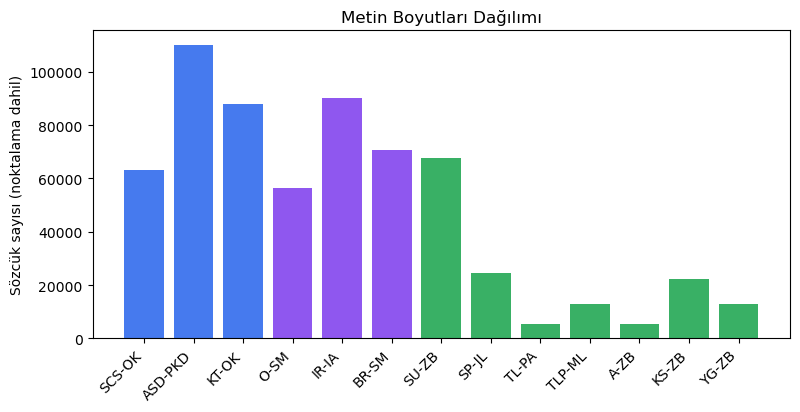

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
d = sizes.merge(loader.registry.inventory()[["code", "focal_code", "year"]], on="code")
ax.bar(d["code"], d["tokens"], color=[viz.color_for(c) for c in d["focal_code"]],
       alpha=0.85)
ax.set_ylabel("Sözcük sayısı (noktalama dahil)"); ax.set_title("Metin Boyutları Dağılımı")
plt.xticks(rotation=45, ha="right"); plt.show()

<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Buradaki `tokens` sütunu noktalama işaretlerini de içerir; sonraki analizlerde noktalama elenerek *akan sözcükler (running words)* kullanılır.
- Metin uzunluklarını kontrol etmeden yazarlar arası istatistiksel genellemeler yapmayın.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Hangi yazar-çevirmen en büyük *yerli* metne sahiptir ve kaç sözcükten oluşur?

<details><summary>Çözümü Göster</summary>

```python
sizes[sizes['type']=='indigenous'].nlargest(1,'tokens')[['author_translator','title','tokens']]
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Derlem Temsiliyeti ve Yazar-Çevirmen Örneklemesi (Toury 2012; Biber 1988):**
Selma Mine, Zühtü Bayar ve Özlem Kurdoğlu üçlüsü, modern Türk bilimkurgu yazınının kurucu
kuşağını teşkil eder. Hem çeviri yapıtlarının hem de özgün romanlarının derleme dahil edilmesi,
çeviri normlarının yerli yazar habitusuna aktarımını incelemek için doğal bir yarı-deneysel
karşılaştırma olanağı sunar.

</div>

---
# Bölüm 2 · Tembel Yükleme ve Bellek Yönetimi (RAM)
⏱ ~15 dk · 📚 Önkoşullar: Bölüm 0–1

> İhtiyacın olanı yükle, işin bittiğinde belleği geri ver.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- 8 farklı derlem yükleyici yöntemini kullanabilme
- Sözcük ve tümce tablolarının bellek dostu mimarisini inceleme
- Süreç belleğini ölçme ve `evict()` ile RAM'i serbest bırakma

### 2.1 Sekiz Temel Derlem Yükleyici
| Yöntem | Döndürdüğü Nesne | Kapsam |
|---|---|---|
| `load_all_english()` | CorpusSelection | 5 İngilizce kaynak roman |
| `load_all_turkish()` | CorpusSelection | 5 çeviri + 3 yerli roman |
| `load_translation_pairs([author])` | ParallelCorpus | 5 hizalanmış çeviri çifti |
| `load_indigenous([author])` | CorpusSelection | 3 yerli Türkçe roman |
| `load_all()` | CorpusSelection | 13 metnin tamamı |
| `load_author_related([author])` | CorpusSelection | Belirli bir yazarın tüm kaynak, çeviri ve yerli metinleri |
| `load_author_turkish([author])` | CorpusSelection | Belirli bir yazarın yalnızca Türkçe metinleri |
| `load_text(code_or_title)` | LazyCorpusText | Belirli bir tekil metin (`'BR-SM'` veya `'Karanlığı Taramak'`) |

`author` parametresi kısa kod (`'SM'`) **veya** tam yazar adı (`'Selma Mine'`, `'ozlem kurdoglu'`) kabul eder.

### 2.2 Adım Adım Bellek Yaşam Döngüsü: Yükle, Ölç ve Tahliye Et
1. Yükleyici çağrıldığında veri tablosu henüz belleğe açılmaz (`text.is_loaded() == False`).
2. `text.tokens` erişildiğinde Parquet/pickle tablosu RAM'e alınır (`text.is_loaded() == True`).
3. `text.evict()` çağrıldığında tablo bellekten silinir ve çöp toplayıcı (`gc.collect()`) çalıştırılır.

In [7]:
toy_t = loader.load_text("BR-SM")
print("tokens erişiminden önce:", toy_t.is_loaded())
_ = toy_t.tokens
print("tokens erişiminden sonra:", toy_t.is_loaded(), f"({toy_t.memory_mb():.1f} MB)")
toy_t.evict()
print("evict() sonrasında:", toy_t.is_loaded())

tokens erişiminden önce: True
tokens erişiminden sonra: True (8.0 MB)
evict() sonrasında: False


### 📋 Komut ve İşlev Kılavuzu · Yükleme ve Bellek Yönetimi

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `loader.load_all_english()` | 5 İngilizce kaynak bilimkurgu metni | `loader.load_all_english()` |
| `loader.load_all_turkish()` | 5 çeviri + 3 yerli Türkçe bilimkurgu romanı | `loader.load_all_turkish()` |
| `loader.load_translation_pairs(author=None)` | 5 paralel hizalanmış çeviri çifti | `loader.load_translation_pairs('SM')` |
| `loader.load_indigenous(author=None)` | 3 yerli Türkçe bilimkurgu romanı | `loader.load_indigenous('ZB')` |
| `loader.load_all()` | Odak derlemdeki 13 metnin tamamı | `loader.load_all()` |
| `loader.load_text(identifier)` | Kod veya başlık alt-dizesiyle tekil metin yükleme | `loader.load_text('BR-SM')` |
| `text.evict()` | DataFrame belleğini serbest bırakır ve gc.collect() tetikler | `text.evict()` |

In [8]:
loader.load_all_english().describe()
loader.load_all_turkish().describe()
loader.load_translation_pairs().describe()
loader.load_indigenous().describe()
loader.load_author_related("Özlem Kurdoğlu").describe()
loader.load_author_turkish("zuhtu bayar").describe();

📚 All English texts (sources) — 5 text(s)
  • Philip K. Dick — A Scanner Darkly [ASD-PKD] (1977, English source; source author: Philip K. Dick; related to Özlem Kurdoğlu)
  • Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
  • Jack London — The Scarlet Plague [SP-JL] (1912, English source; source author: Jack London; related to Zühtü Bayar)
  • Poul Anderson — The Light [TL-PA] (1957, English source; source author: Poul Anderson; related to Zühtü Bayar)
  • Murray Leinster — The Lonely Planet [TLP-ML] (1949, English source; source author: Murray Leinster; related to Zühtü Bayar)
📚 All Turkish texts (translations + indigenous) — 8 text(s)
  • Özlem Kurdoğlu — Son Cephede Şafak [SCS-OK] (2000, Turkish indigenous)
  • Özlem Kurdoğlu — Karanlığı Taramak [KT-OK] (1998, Turkish translation)
  • Selma Mine — OBİ,J.S.927 [O-SM] (1980, Turkish indigenous)
  • Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation

### 2.3 Sözcük ve Tümce Tablolarının Yapısı
Her sözcükbirim bir satırdır; sütunlar: `sid` (tümce), `ti` (konum), `tok`, `lem`, `pos` (UPOS),
`morph`, `head`, `rel` (bağımlılık), `fcl` (0 içerik / 1 işlevsel / 2 noktalama).

In [9]:
import time
text = loader.load_text("Ben, Robot: Mekanik Adam Devri")     # henüz tembel (lazy) …
print(loader.registry.display(text))
t0 = time.perf_counter(); tab = text.tokens                    # … şimdi belleğe alındı
print(f"{len(tab):,} sözcük {time.perf_counter()-t0:.2f} sn içinde · tablo ≈ {text.memory_mb():.1f} MB")
display(tab.head(8))

Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
70,629 sözcük 0.19 sn içinde · tablo ≈ 7.2 MB


,sid,ti,tok,lem,pos,morph,head,rel,fcl
0,0,0,Ben,ben,PRON,ben+Pron+Pers+A1sg+Pnon+Nom,0,root,1
1,0,1,",",",",PUNCT,",+Punc",3,punct,2
2,0,2,Robot,robot,NOUN,robot+Noun+A3sg+Pnon+Nom,1,conj,0
3,0,3,:,:,PUNCT,:+Punc,3,punct,2
4,1,0,Mekanik,mekanik,ADJ,mekanik+Noun+A3sg+Pnon+Nom,2,amod,0
5,1,1,Adam,adam,NOUN,adam+Noun+A3sg+Pnon+Nom,0,root,0
6,1,2,Devri,devir,NOUN,devir+Noun+A3sg+P3sg+Nom,2,flat,0
7,2,0,Bir,bir,DET,bir+Det,2,det,1


In [10]:
# Soğuk vs sıcak yükleme: tahliye et, ardından Parquet önbellekten yeniden yükle
text.evict(verbose=True)
t0 = time.perf_counter(); _ = text.tokens
print(f"önbellekten yeniden yükleme: {time.perf_counter()-t0:.3f} sn")
display(loader.memory_report())

♻️  evicted BR-SM: RSS 394 → 394 MB
önbellekten yeniden yükleme: 0.081 sn
Process RSS: 403 MB | tables in RAM: 56 MB


,code,loaded,table_mb
0,SCS-OK,True,7.5
1,ASD-PKD,True,4.9
2,KT-OK,True,9.3
3,O-SM,True,5.7
4,IR-IA,True,4.3
5,BR-SM,True,7.2
6,SU-ZB,True,8.1
7,SP-JL,True,1.3
8,TL-PA,True,0.4
9,TLP-ML,True,0.8


In [11]:
# Çok sayıda metin üzerinde bellek korumalı döngü: her metin kullanımdan hemen sonra tahliye edilir
rows = []
for t in loader.load_all().iter_evicting():
    n = len(TokenView(t, "lem", filter_function_words=True))
    rows.append((t.record.focal_name, t.record.title, n))
pd.DataFrame(rows, columns=["author_translator", "title", "content_lemmas"])

,author_translator,title,content_lemmas
0,Özlem Kurdoğlu,Son Cephede Şafak,39252
1,Özlem Kurdoğlu,A Scanner Darkly,44088
2,Özlem Kurdoğlu,Karanlığı Taramak,51449
3,Selma Mine,"OBİ,J.S.927",30966
4,Selma Mine,"I, Robot",36349
5,Selma Mine,"Ben, Robot: Mekanik Adam Devri",40115
6,Zühtü Bayar,Sahte Uygarlık,45638
7,Zühtü Bayar,The Scarlet Plague,10038
8,Zühtü Bayar,The Light,2070
9,Zühtü Bayar,The Lonely Planet,6039


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Bir değişkende tutulan `LazyCorpusText`, `.evict()` çağrılana (veya `iter_evicting()` kullanılana) dek tablolarını RAM'de tutar.
- Bir `.pickle.xz` dosyasının güncellenmesi önbellek kaydını otomatik olarak geçersiz kılar; `.cache/` dizinini silmek her zaman güvenlidir.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Zühtü Bayar'ın çeviri çiftlerini yükleyiniz ve her İngilizce/Türkçe metnin tümce sayısını yazdırınız.

<details><summary>Çözümü Göster</summary>

```python
for pair, en, tr in loader.load_translation_pairs('ZB'):
    print(en.summary()['title'], en.summary()['n_sentences'], '→', tr.summary()['title'], tr.summary()['n_sentences'])
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Dijital Çeviribilimde Hesaplamalı Bellek Korunumu (Sinclair 1991):**
Kitap uzunluğundaki paralel ve karşılaştırılabilir derlemlerin analizi disiplinli bir bellek
yönetimi gerektirir. DataFrame yapılarını yalnızca talep anında belleğe açarak, optimize edilmiş
sütun tiplerini Parquet olarak önbellekleyerek ve işi biten yapıları tahliye ederek yüz binlerce
etiketli sözcüğü 1.5 GB RAM sınırının altında analiz edebiliyoruz.

</div>

---
# Bölüm 3 · Paralel Derlem Hizalama Yapısı ve NDA Yan Yana Görünüm
⏱ ~20 dk · 📚 Önkoşullar: Bölüm 0–2

> Çevirmenler tümceleri nasıl böler, birleştirir ve yeni sözcükleri nasıl aktarır?

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Tümce hizalamalarını 1:1, 1:N, N:1, N:M, atlama (omission) ve ekleme (addition) olarak sınıflandırma
- `R_sent`, sözcük ve karakter genişleme oranlarını hesaplayıp yorumlama
- Neologism Dictionary Annotation (NDA) yan yana paralel görünümüyle İngilizce ⇄ Türkçe hizalı öğeleri inceleme

### 3.1 Kuramsal Arka Plan: Çeviri Hizalaması
Tümce hizalayıcı, İngilizce ve Türkçe tümce *gruplarını* eşleştirir. Grubun **kardinalite şekli**
çevirmen kararlarının somut izidir (Toury 2012: *yeterlik* vs *benimsenirlik*; Baker 1993:
*açıklayıcılık, sadeleştirme*):

| Tür | (İngilizce, Türkçe) | Okuma |
|---|---|---|
| 1:1 | (1, 1) | Tümce sınırı korunmuş |
| 1:N | (1, n≥2) | İngilizce tümce **bölünmüş** |
| N:1 | (n≥2, 1) | Tümceler **birleştirilmiş** |
| N:M | (n≥2, m≥2) | Yeniden yapılandırılmış |
| omission | (n, 0) | Türkçe karşılığı olmayan İngilizce tümce |
| addition | (0, m) | İngilizce karşılığı olmayan Türkçe tümce |

`R_sent = Türkçe tümce sayısı ÷ İngilizce tümce sayısı` (>1: Türkçe çeviri daha fazla tümce kullanır).

### 3.2 Adım Adım Oyuncak Örnek
Altı hizalama grubu: şekiller (1,1), (1,1), (1,2), (2,1), (1,0), (0,1).
İngilizce tümceler = 1+1+1+2+1+0 = 6; Türkçe = 1+1+2+1+0+1 = 6 → `R_sent = 1.0`.
İki grupta yeniden yapılandırma olmasına rağmen genel oran 1.0 çıkabilir — *1'e yakın bir oran zıt yönlü hareketleri gizleyebilir*.

In [12]:
toy = [(1,1),(1,1),(1,2),(2,1),(1,0),(0,1)]
print([alignment.alignment_type(a, b) for a, b in toy])
print("R_sent =", sum(b for _, b in toy) / sum(a for a, _ in toy))

['1:1', '1:1', '1:N', 'N:1', 'omission', 'addition']
R_sent = 1.0


### 📋 Komut ve İşlev Kılavuzu · Hizalama ve NDA Yan Yana Paralel Görünüm Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `alignment.alignment_type(n_en, n_tr)` | Kardinaliteyi '1:1', '1:N', 'N:1', 'N:M', 'omission', 'addition' olarak sınıflandırır | `alignment.alignment_type(1, 2)` |
| `AlignmentStructureAnalyzer(cache).summary(pairs)` | Tüm çeviri çiftleri için yüzde dağılımı ve R_sent özet tablosu | `ana.summary(pairs)` |
| `AlignmentStructureAnalyzer.cardinality_table(pair)` | Hizalama grubu başına sözcük sayısı ve tür tablosu | `ana.cardinality_table(pair)` |
| `show_parallel(loader, pair_or_code, ais, overlay=True)` | NDA sözlük bağlantıları, SVG çizgileri ve sözlükbirimlerle EN ⇄ TR yan yana görünüm | `show_parallel(loader, 'I_Robot', [3350, 4288, 4313])` |
| `AlignmentIndex.texts(ai)` | ai numaralı hizalama grubu için (eng_text, tur_text) döndürür | `idx.texts(14)` |

In [13]:
pairs = [p for p, _, _ in loader.load_translation_pairs()]
ana = alignment.AlignmentStructureAnalyzer(loader.cache)
summary = ana.summary(pairs)
show_table(summary.round(2), page_size=20, title="Paralel Hizalama Yapısı Özeti")

pair⇅,translator⇅,alignments⇅,eng_sentences⇅,tur_sentences⇅,1:1_n⇅,1:1_pct⇅,1:N_n⇅,1:N_pct⇅,N:1_n⇅,N:1_pct⇅,N:M_n⇅,N:M_pct⇅,omission_n⇅,omission_pct⇅,addition_n⇅,addition_pct⇅,R_sent⇅,word_ratio⇅,char_ratio⇅
A Scanner Darkly → Karanlığı Taramak,Özlem Kurdoğlu,"7,434","7,652","8,268","6,534",87.890,666,8.960,161,2.170,47,0.630,24,0.320,2,0.030,1.080,0.800,1.050
"I, Robot → Ben, Robot: Mekanik Adam Devri",Selma Mine,"6,431","6,591","7,612","4,776",74.270,"1,078",16.760,176,2.740,82,1.280,198,3.080,121,1.880,1.150,0.730,0.990
The Light → Kıyametten Sonra: Aydınlık,Zühtü Bayar,373,364,460,186,49.870,72,19.300,23,6.170,15,4.020,24,6.430,53,14.210,1.260,1.050,1.460
The Scarlet Plague → Kıyametten Sonra: Kıyametten Sonra,Zühtü Bayar,"1,407","1,362","1,847",697,49.540,265,18.830,62,4.410,71,5.050,83,5.900,229,16.280,1.360,0.910,1.260
The Lonely Planet → Kıyametten Sonra: Yalnız Gezegen,Zühtü Bayar,734,782,885,453,61.720,117,15.940,46,6.270,30,4.090,43,5.860,45,6.130,1.130,0.960,1.290


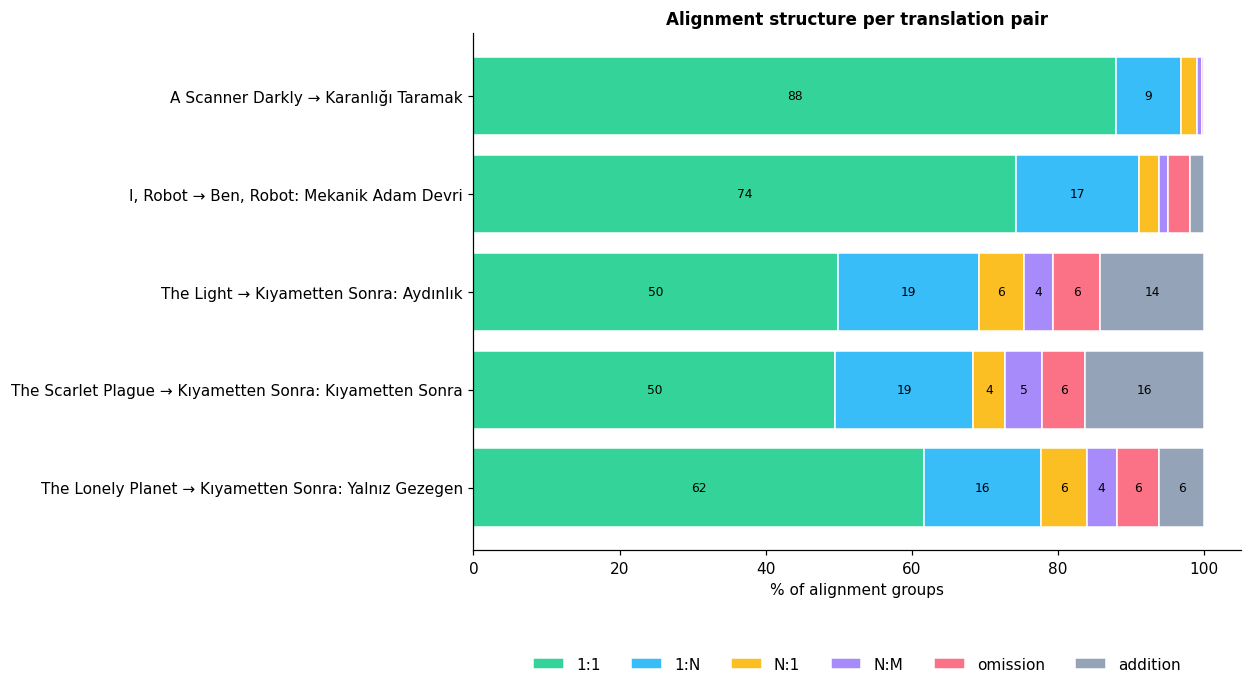

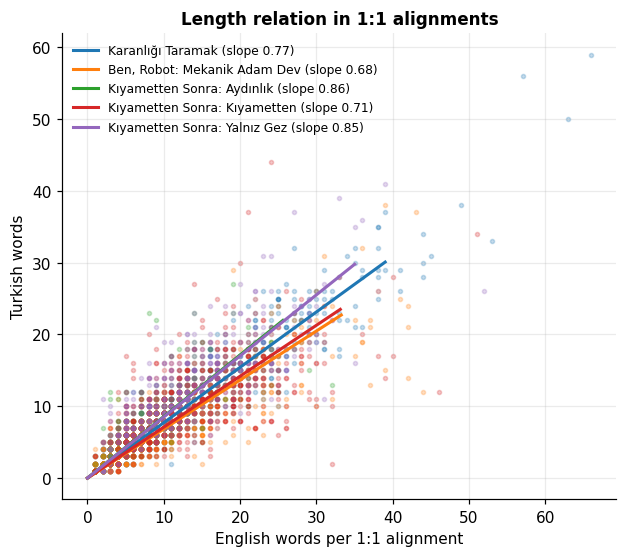

In [14]:
fig = viz.alignment_stacked(summary); plt.show()                       # Şekil 1A
tables = {p.tur.title[:28]: ana.cardinality_table(p) for p in pairs}
fig = viz.alignment_scatter(tables); plt.show()                        # Şekil 1B

### 3.3 Yorumlama Kılavuzu ve NDA Yan Yana Paralel Derlem Görünümü
- **Yüksek 1:1** → Çeviri tümce sınırlarını korur; yüksek **1:N** → İngilizce uzun tümceler Türkçede bölünmüştür.
- **omission / addition** çevirmen kararı olabileceği gibi **hizalayıcı/baskı farkı** da olabilir; yorumlamadan önce örnekleri inceleyin.
- **`show_parallel(loader, pair, ais)`** işlevi, `scripts/Neologism_Dictionary_Annotation` (NDA) aracının
  yöntembilimini ve veri akışını içe aktarır: her sözcük iki katmanlı bir kapsül (`yüzey biçim` + `lemma·UPOS`)
  olarak çizilir; eşlenmiş iki dilli yeni sözcükler (`initial_dictionary.pickle`) **SVG bağlantı çizgileriyle (`L#`)**
  birleştirilir; tek dilli *Gerçekdışı Özolgular* (`single_eng` camgöbeği / `single_tur` gül kurusu) ve yüksek
  adaylık puanlı sözcükler (`scored_alignment_rows.pickle`) renklendirilir; her `ai` grubunun altında
  **Etiket Atamaları Özeti (Current Label Attributions)** yer alır.

In [15]:
# NDA yan yana paralel görünüm: eşlenmiş iki dilli çiftler (L#), tek dilli özolgular ve SVG bağlantı çizgileri
show_parallel(loader, "I_Robot", [3350, 4288, 4313], overlay=True, hits={"brain"})

In [16]:
# Bir çeviri çiftindeki ilk atlamaları (omission) doğrudan metin üzerinde inceleyelim
pair = pairs[1]
idx = loader.alignment_index(pair)
tab = ana.cardinality_table(pair)
for ai in tab[tab["type"] == "omission"]["ai"].head(3):
    print(ai, "| EN:", idx.texts(ai)[0][:120])

2 | EN: John W. Campbell, JR., who godfathered the robots
3 | EN: Three Laws of Robotics
12 | EN: Introduction


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Yüzdeler *hizalama grupları* üzerinden, `R_sent` ise *tümceler* üzerinden hesaplanır — ikisi farklı sorulara yanıt verir.
- Çok kısa metinler (*The Light*) yüzdelerde dalgalanmaya yol açabilir.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Hangi çeviri çifti en yüksek N:M yeniden yapılandırma oranına sahiptir?

<details><summary>Çözümü Göster</summary>

```python
summary.loc[summary['N:M_pct'].idxmax(), ['pair','N:M_pct']]
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çeviri Normları ve Sentaktik Yeniden Yapılanma (Toury 2012; Baker 1993):**
Toury, kaynak odaklı *yeterlik (adequacy)* ile erek odaklı *benimsenirlik (acceptability)*
arasındaki gerilimi tanımlar. $R_{\text{sent}}$ oranı ve 1:N bölme yüzdeleri, çevirmenin
İngilizce karmaşık tümceleri Türkçe tümce normlarına nasıl uyarladığını somutlaştırır.

</div>

---
# Bölüm 4 · Sözcük Türü (POS) Karşılaştırmalı Analizi
⏱ ~25 dk · 📚 Önkoşullar: Bölüm 0–2

> Çevirmenler kendi telif romanlarını çevirdikleri kitaplardan farklı mı yazarlar?

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Evrensel Sözcük Türü (UPOS) profillerini, sözcüksel yoğunluğu ve ad/eylem oranlarını hesaplama
- Bir çeviri çifti içinde İngilizce kaynak ile Türkçe çeviriyi karşılaştırma
- Çeviri ve yerli Türkçe metinler arasındaki farkları bootstrap güven aralıklarıyla test etme

### 4.1 Kuramsal Temel: Sözcük Türleri ve Biçem
UPOS (Evrensel Sözcük Türleri, Nivre vd. 2016) diller arası karşılaştırılabilir bir etiket kümesi sunar.
İki klasik gösterge: **sözcüksel yoğunluk (lexical density)** = içerik sözcükleri ÷ akan sözcükler
(Ure 1971; Halliday 1985) ve **ad/eylem oranı (noun/verb ratio)** (Biber 1988).
Tablolarımızda sözcüksel yoğunluk = (NOUN+VERB+ADJ+ADV) ÷ noktalama dışı sözcükler × 100 olarak hesaplanır.
İngilizce ve Türkçe *tipolojik* olarak farklılaştığından İngilizce↔Türkçe farkları kalite değil **yapısal profil**
farkıdır. Tez için asıl anlamlı karşılaştırma Türkçe içindeki **çeviri ↔ yerli** karşılaştırmasıdır (Simeoni 1998).

### 4.2 Adım Adım Oyuncak Örnek
Cümle: “The cat saw the dog .” → etiketler DET NOUN VERB DET NOUN PUNCT. Noktalama dışı sözcük = 5;
içerik sözcükleri = NOUN, VERB, NOUN = 3 → sözcüksel yoğunluk %60; ad/eylem oranı = 2.

### 📋 Komut ve İşlev Kılavuzu · Sözcük Türü (POS) Analiz Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `PosComparativeAnalyzer().profile_table(texts)` | Her metin için UPOS % sütunları ve yoğunluk metrikleri | `P.profile_table(loader.load_all())` |
| `PosComparativeAnalyzer().pair_comparison(en, tr)` | Paralel çeviri çifti için doğrudan UPOS karşılaştırması | `P.pair_comparison(en, tr)` |
| `PosComparativeAnalyzer().group_comparison(g1, g2, labels)` | Alt derlemler arası ortalama farkların bootstrap güven aralıkları | `P.group_comparison(trans, indig, ('translation', 'indigenous'))` |

code⇅,title⇅,language⇅,type⇅,focal⇅,NOUN⇅,VERB⇅,ADJ⇅,ADV⇅,PROPN⇅,NUM⇅,PRON⇅,DET⇅,ADP⇅,AUX⇅,CCONJ⇅,SCONJ⇅,PART⇅,INTJ⇅,SYM⇅,X⇅,tokens_nonpunct⇅,lexical_density⇅,lexical_density_propn⇅,function_share⇅,noun_verb_ratio⇅,deverbal_share⇅
SCS-OK,Son Cephede Şafak,tr,indigenous,Özlem Kurdoğlu,34.500,20.000,11.500,8.500,4.200,1.300,5.800,5.200,3.300,1.600,3.900,0.200,0.000,0.200,0.000,0.000,"49,563.000",74.400,78.600,20.800,1.700,10.200
ASD-PKD,A Scanner Darkly,en,source,Özlem Kurdoğlu,15.800,16.400,5.700,6.900,4.300,1.000,15.900,8.300,10.300,6.100,3.800,2.300,2.700,0.600,0.000,0.100,"87,994.000",44.800,49.000,49.900,1.000,—
KT-OK,Karanlığı Taramak,tr,translation,Özlem Kurdoğlu,31.000,20.600,10.600,8.100,5.100,1.000,6.900,6.100,3.400,1.800,4.800,0.200,0.000,0.200,0.000,0.000,"67,933.000",70.400,75.500,24.300,1.500,8.100
O-SM,"OBİ,J.S.927",tr,indigenous,Selma Mine,35.000,21.400,11.300,6.200,3.700,1.000,6.100,5.300,3.300,1.700,4.800,0.200,0.000,0.100,0.000,0.000,"39,695.000",73.800,77.600,22.000,1.600,7.700
IR-IA,"I, Robot",en,source,Selma Mine,15.800,14.700,6.800,6.500,5.100,1.200,14.200,8.900,9.600,7.200,3.500,2.300,3.300,0.700,0.000,0.100,"72,429.000",43.800,49.000,49.800,1.100,—
BR-SM,"Ben, Robot: Mekanik Adam Devri",tr,translation,Selma Mine,32.800,20.100,11.100,7.400,5.700,1.400,5.700,6.200,3.000,1.900,4.200,0.300,0.000,0.300,0.000,0.000,"51,632.000",71.300,77.000,22.300,1.600,8.600
SU-ZB,Sahte Uygarlık,tr,indigenous,Zühtü Bayar,37.700,17.300,13.200,6.400,6.100,1.300,3.300,6.200,2.100,1.100,5.000,0.100,0.000,0.100,0.000,0.100,"55,953.000",74.700,80.800,18.400,2.200,8.500
SP-JL,The Scarlet Plague,en,source,Zühtü Bayar,18.400,12.900,6.800,5.200,3.900,1.600,13.200,11.000,11.200,6.200,5.000,2.500,2.000,0.200,0.000,0.000,"20,596.000",43.200,47.100,51.300,1.400,—
TL-PA,The Light,en,source,Zühtü Bayar,15.400,14.800,6.500,6.600,3.300,0.800,13.900,10.600,9.200,8.200,4.400,2.800,2.900,0.500,0.000,0.100,"4,367.000",43.300,46.600,52.600,1.000,—
TLP-ML,The Lonely Planet,en,source,Zühtü Bayar,20.500,13.700,6.700,5.300,4.400,1.800,9.300,10.400,11.600,7.000,3.700,2.600,2.900,0.000,0.000,0.000,"11,517.000",46.200,50.600,47.600,1.500,—


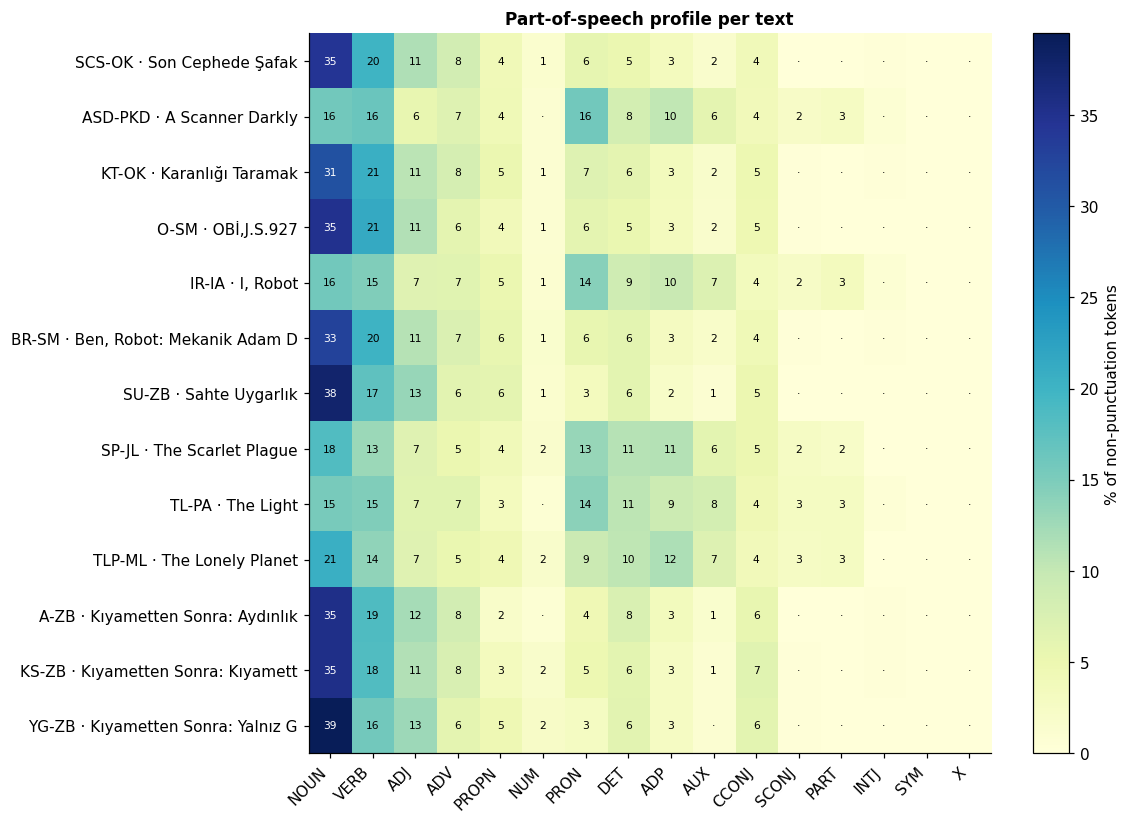

In [17]:
P = pos.PosComparativeAnalyzer()
profile = P.profile_table(loader.load_all())
show_table(profile.round(1), page_size=50, title="13 Metnin UPOS Profil Tablosu")
fig = viz.pos_heatmap(profile, pos.UPOS_ORDER); plt.show()             # Şekil 2A

### 4.3 Tek Bir Çeviri Çifti Karşılaştırması (Şekil 2B)
Kodları Bölüm 2'de listelenen herhangi bir çeviri çiftiyle değiştirebilirsiniz (`IR-IA ⇄ BR-SM`, `ASD-PKD ⇄ KT-OK`, …).

Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)


pos⇅,English %⇅,Turkish %⇅,Δ (TR−EN) pp⇅
NOUN,15.800,32.800,16.900
VERB,14.700,20.100,5.400
ADJ,6.800,11.100,4.300
ADV,6.500,7.400,0.800
PROPN,5.100,5.700,0.600
NUM,1.200,1.400,0.300
PRON,14.200,5.700,-8.600
DET,8.900,6.200,-2.700
ADP,9.600,3.000,-6.600
AUX,7.200,1.900,-5.300


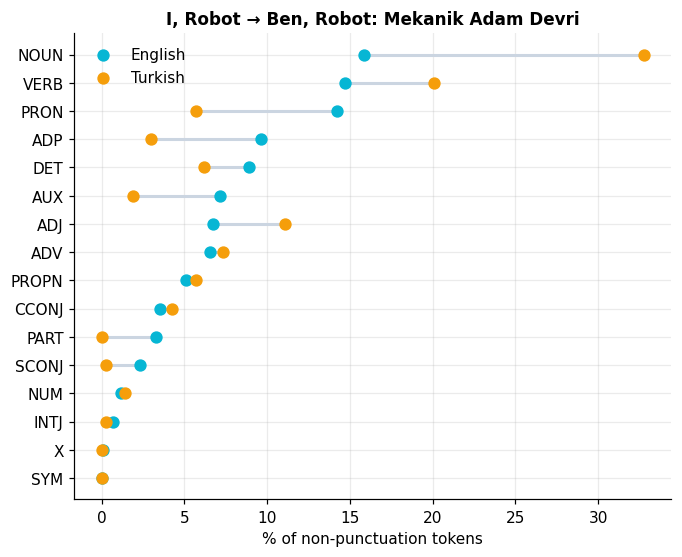

In [18]:
en, tr = loader.load_text("IR-IA"), loader.load_text("BR-SM")
print(loader.registry.display(en)); print(loader.registry.display(tr))
cmp_df = P.pair_comparison(en, tr)
show_table(cmp_df.round(1), page_size=20, title="Çift UPOS Karşılaştırması: I, Robot ⇄ Ben, Robot")
fig = viz.pos_pair(cmp_df, f"{en.record.title} → {tr.record.title}"); plt.show()
en.evict(); tr.evict()

### 4.4 Çeviri ve Yerli Türkçe Metinlerin Grup Karşılaştırması (Şekil 2C)
**Metinler** üzerinden %95 bootstrap güven aralıklı UPOS ortalama farkları, ayrıca birleştirilmiş
sayımlar üzerinden $\chi^2$ ve Cramér V (etki büyüklüğü).

Çeviriler:
 Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
Zühtü Bayar — Kıyametten Sonra: Aydınlık [A-ZB] (1998, Turkish translation)
Zühtü Bayar — Kıyametten Sonra: Yalnız Gezegen [YG-ZB] (1998, Turkish translation)
Zühtü Bayar — Kıyametten Sonra: Kıyametten Sonra [KS-ZB] (1998, Turkish translation)
Özlem Kurdoğlu — Karanlığı Taramak [KT-OK] (1998, Turkish translation)
Yerli Romanlar:
 Özlem Kurdoğlu — Son Cephede Şafak [SCS-OK] (2000, Turkish indigenous)
Selma Mine — OBİ,J.S.927 [O-SM] (1980, Turkish indigenous)
Zühtü Bayar — Sahte Uygarlık [SU-ZB] (1999, Turkish indigenous)


UPOS⇅,translation mean %⇅,indigenous mean %⇅,mean diff pp⇅,CI95 low⇅,CI95 high⇅
NOUN,34.820,35.730,-0.910,-3.950,1.990
VERB,18.700,19.580,-0.880,-3.200,1.540
ADJ,11.580,11.990,-0.410,-1.610,0.720
ADV,7.520,7.020,0.500,-0.840,1.730
PROPN,4.110,4.660,-0.550,-2.320,0.890
NUM,1.450,1.200,0.250,-0.220,0.760
PRON,4.940,5.050,-0.100,-1.850,1.730
DET,6.510,5.560,0.960,0.320,1.590
ADP,3.030,2.890,0.140,-0.500,0.850
AUX,1.420,1.450,-0.030,-0.470,0.430


{'chi2': 633.4684601894703, 'p': 5.575166428862409e-127, 'cramers_v': 0.04604506633622353, 'n_a': 5, 'n_b': 3}


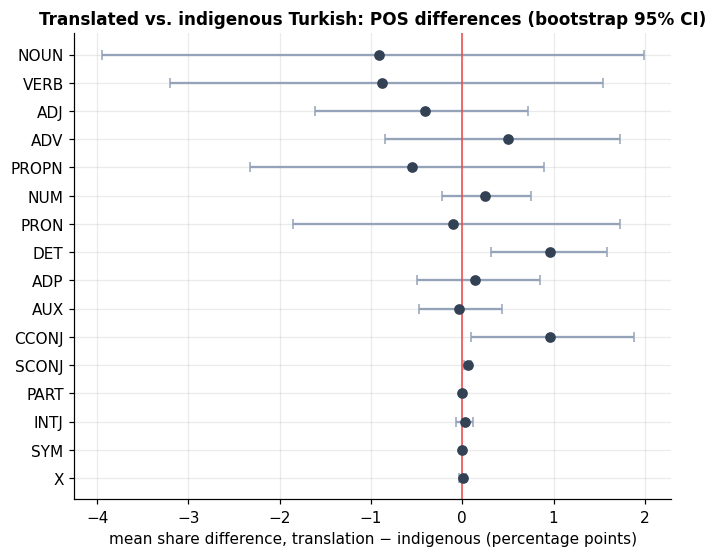

In [19]:
trans = [loader.load_text(c) for c in ["BR-SM", "A-ZB", "YG-ZB", "KS-ZB", "KT-OK"]]
indig = list(loader.load_indigenous())
print("Çeviriler:\n", "\n".join(loader.registry.display(t) for t in trans))
print("Yerli Romanlar:\n", "\n".join(loader.registry.display(t) for t in indig))
grp = P.group_comparison(trans, indig, ("translation", "indigenous"))
show_table(grp.round(2), page_size=20, title="Çeviri vs Yerli Türkçe UPOS (Bootstrap %95 GA)")
print(grp.attrs)
fig = viz.pos_group(grp, ("translation", "indigenous")); plt.show()

In [20]:
# Aynı soruyu yalnızca içerik sözcükleriyle (işlevsel sözcükler gizlenmiş) inceleyelim
grp_c = P.group_comparison(trans, indig, ("translation", "indigenous"), content_only=True)
show_table(grp_c.round(2), page_size=20, title="Yalnızca İçerik Sözcükleri UPOS Karşılaştırması")

UPOS⇅,translation mean %⇅,indigenous mean %⇅,mean diff pp⇅,CI95 low⇅,CI95 high⇅
NOUN,44.740,44.790,-0.050,-2.930,2.790
VERB,23.980,24.420,-0.450,-3.930,3.190
ADJ,14.790,14.950,-0.160,-1.380,0.980
ADV,9.390,8.530,0.860,-0.900,2.490
PROPN,5.270,5.810,-0.540,-2.660,1.240
NUM,1.770,1.450,0.320,-0.240,0.930
PRON,0.000,0.000,0.000,0.000,0.000
DET,0.000,0.000,0.000,0.000,0.000
ADP,0.000,0.000,0.000,0.000,0.000
AUX,0.000,0.000,0.000,0.000,0.000


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- İngilizce ve Türkçe için farklı etiketleyiciler kullanıldığından etiket *envanterleri* karşılaştırılabilir olsa da etiketleme *doğruluğu* birebir aynı değildir.
- n=3–5 metinle hesaplanan bootstrap güven aralıkları geniştir — 'kesin kanıtlar' yerine 'uyumludur / işaret eder' dilini kullanın.
- Bir kitap içindeki sözcükler bağımsız değildir: p-değerleri yerine Cramér V etki büyüklüğünü raporlayın.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Yalnızca *yerli* metinler için sözcüksel yoğunluk ortalamasını hesaplayınız.

<details><summary>Çözümü Göster</summary>

```python
profile[profile['type']=='indigenous']['lexical_density'].mean()
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çevirmen Habitusu ve Çeviri Evrenselleri (Simeoni 1998; Toury 2012):**
Çeviri Türkçenin aynı yazarın telif romanlarına kıyasla daha adcil (nominal) veya farklı yoğunlukta
olması kaynak metin baskısıyla (*aktarım / interference*, Toury 2012) uyumludur; ancak aynı
yazar-çevirmenin hem çeviri hem telif yapıtlarını birlikte incelemek, tür farkı ile **habitus**
etkisini ayrıştırmamıza olanak tanır.

</div>

---
# Bölüm 5 · Sözdizimsel Bağımlılık Ağaçları (İngilizce ve Türkçe)
⏱ ~20 dk · 📚 Önkoşullar: Bölüm 0–2

> Sözdizimini görsel ve somut kılma.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Bağımlılık ağacı gösterimini okuma ve yorumlama
- spaCy displaCy tarzında iki dil için de bağımlılık yayları çizdirme
- İşlev sözcüklerini karartarak (dim) ağaç bütünlüğünü bozmadan içeriği vurgulama
- Hizalanmış iki dilli tümce çiftlerinin ağaçlarını alt alta görselleştirme

### 5.1 Kuramsal Çerçeve: Bağımlılık Dilbilgisi
**Bağımlılık Ağacı (Dependency Tree)**, cümledeki her bir sözcüğü (*dependent / bağımlı*)
etiketli bir bağıntıyla bir üst ögeye (*head / baş*) bağlar; cümlenin ana yüklemi ise köktür (baş indeksi 0;
Tesnière 1959; Nivre vd. 2016). Yaylar cümlenin üzerinde gösterilir.

**Görselleştirme Yaklaşımı.** VNLP kütüphanesi doğrudan bir ağaç çizici sunmaz; geliştirdiğimiz
`DependencyVisualizer`, spaCy'nin **displaCy** çizim motorunu harici model gerektirmeksizin (`manual=True`)
çalıştırır. İngilizce etiketler ClearNLP tarzındadır (`dobj, prep, pobj`), Türkçe etiketler ise
Evrensel Bağımlılıklar (UD) biçimindedir (`obj, case, nmod:poss`).

### 5.2 Adım Adım Oyuncak Örnek: 4 Sözcüklü Bir Bağımlılık Ağacı
Cümle: *“Selma robotu gördü .”*
- Sözcükler: `[1: Selma, 2: robotu, 3: gördü, 4: .]`
- Baş İndeksleri: `[3, 3, 0, 3]` (0 = kök / root)
- İlişki Etiketleri: `[nsubj, obj, root, punct]`
- Yaylar: `Selma` (1) $\xrightarrow{\text{nsubj}}$ `gördü` (3); `robotu` (2) $\xrightarrow{\text{obj}}$ `gördü` (3).

### 📋 Komut ve İşlev Kılavuzu · Bağımlılık Ağacı Görselleştirme Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `dv.sid_of(text, (ch, p, s))` | Bölüm, paragraf ve tümce koordinatını sıralı tümce ID'sine çevirir | `sid = dv.sid_of(text, (1, 4, 4))` |
| `dv.table(text, sid)` | Tümcenin (id, token, lemma, pos, head, deprel) tablosunu döndürür | `display(dv.table(text, sid))` |
| `dv.html(text, sid)` | displaCy bağımlılık yaylarını içeren HTML dizesi üretir | `display(HTML(dv.html(text, sid)))` |
| `dv.svg(text, sid)` | Ağacın vektörel SVG çıktısını üretir (makale ve tez için) | `svg_str = dv.svg(text, sid)` |
| `dv.alignment_html(code, ai)` | Hizalama grubundaki İngilizce ve Türkçe tümceleri alt alta dizer | `dv.alignment_html('BR-SM', 4)` |

In [21]:
dv = depviz.DependencyVisualizer(loader)
en = loader.load_text("IR-IA")
print(loader.registry.display(en))
sid = dv.sid_of(en, (1, 4, 4))            # Asimov'un ünlü 'Üç Robot Yasası' tümcesi
display(dv.table(en, sid))

Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)


,idx,word,lemma,upos,head,head_word,deprel
0,1,1,1,X,6,not,meta
1,2,—,—,PUNCT,6,not,punct
2,3,A,a,DET,3,A,det
3,4,robot,robot,NOUN,6,not,nsubj
4,5,may,may,AUX,6,not,aux
5,6,not,not,PART,6,not,neg
6,7,injure,injure,VERB,6,not,ROOT
7,8,a,a,DET,9,human,det
8,9,human,human,NOUN,9,human,compound
9,10,being,being,NOUN,6,not,dobj


In [22]:
display(HTML(style.CSS + "<div class='ct'>" + dv.html(en, sid) + "</div>"))

In [23]:
tr = loader.load_text("BR-SM")
print(loader.registry.display(tr))
sid_tr = dv.sid_of(tr, (1, 2, 3))         # Selma Mine'nin Türkçe çevirisi
display(dv.table(tr, sid_tr))
display(HTML(style.CSS + "<div class='ct'>" + dv.html(tr, sid_tr) + "</div>"))

Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)


,idx,word,lemma,upos,head,head_word,deprel
0,1,Bir,bir,DET,2,robot,det
1,2,robot,robot,NOUN,6,veremez,nsubj
2,3,",",",",PUNCT,2,robot,punct
3,4,insana,insan,NOUN,6,veremez,obl
4,5,zarar,zarar,NOUN,6,veremez,compound
5,6,veremez,ver,VERB,0,ROOT,root
6,7,;,;,PUNCT,6,veremez,punct
7,8,hatta,hatta,CCONJ,17,vermesine,cc
8,9,",",",",PUNCT,11,kalarak,punct
9,10,etkisiz,etki,ADJ,11,kalarak,advmod


### 5.3 İki Dilli Hizalanmış Çift Ağaç Görünümü
`alignment_html(code, ai)` işlevi, `ai` hizalama grubundaki tüm İngilizce tümcelerin ağaçlarını,
ardından Türkçe karşılıklarının ağaçlarını alt alta çizer.

In [24]:
display(HTML(style.CSS + dv.alignment_html("BR-SM", 4)))

In [25]:
# UD-normalize etiketler yerine ham etiketler ve yalnızca içerik sözcükleri vurgulanmış görünüm
display(HTML(style.CSS + "<div class='ct'>" + dv.html(en, sid, normalize_labels=False,
                                                   dim_function_words=True) + "</div>"))
for t in (en, tr): t.evict()

<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- İşlev sözcükleri ağaç bütünlüğünü korumak için silinmez, yalnızca rengi soluklaştırılır (*dimmed*).
- Ayrıştırıcı çıktıları istatistiksel modellerce tahmin edilmiştir; uzun ve karmaşık edebi tümcelerde etiket hataları görülebilir.
- Çok uzun tümceler yatay kaydırma gerektirir; sıkıştırmak için `compact=True` kullanabilirsiniz.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** *Karanlığı Taramak* çevirisinin ilk tümcesinin bağımlılık ağacını çizdiriniz ve kök (root) sözcüğünü bulunuz.

<details><summary>Çözümü Göster</summary>

```python
t=loader.load_text('KT-OK'); s=dv.sid_of(t,(1,1,1)); tab=dv.table(t,s); tab[tab['deprel']=='root']
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çeviride Yapısal Kaymalar ve Bağımlılık Sözdizimi (Catford 1965; Tesnière 1959):**
İngilizce tümce düzeyinde başı-önde (*head-initial, SVO*), Türkçe ise başı-sonda (*head-final, SOV*)
bir dil tipolojisine sahiptir. İki dilli bağımlılık ağaçlarının karşılaştırılması, Catford'un
*birim kayması (unit shift)* ve *yapı kayması (structure shift)* kavramlarını somut biçimde
resmeder: İngilizce ilgeç öbekleri (`prep + pobj`) Türkçede ad durum eklerine dönüşür;
bağıntı tümceleri ise eylemsi öbeklerine sıkıştırılır.

</div>

---
# Bölüm 6 · Derlem Arama Motoru ve Düğüm Sözcük Sorgulama
⏱ ~25 dk · 📚 Önkoşullar: Bölüm 0–2

> Merak ettiğiniz her sözcüksel örüntüyü derlemde bulup ortaya çıkarma.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Sözcükbirim (token), sözlükbirim (lemma), joker karakter (glob), düzenli ifade (regex) ve UPOS etiketine göre arama yapabilme
- Bağlam sözcüğü kısıtı ekleyebilme (eşdizimli sözcük filtreleme)
- İçerik sözcüğü görünümünde arama yapabilme (işlevsel sözcükler gizlenmiş) ve `drop` ile `mask` farkını kavrama
- Noktalama işaretlerini koruma/çıkarma/ayırma (`keep`, `drop`, `strip`, `split`) ve Türkçe kesme işareti düzeltmesini anlama

### 6.1 Kuramsal Çerçeve: Düğüm Sözcük ve Arama Parametreleri
Derlembilimde aradığınız temel hedef sözcüğe **düğüm sözcük (node word)** adı verilir (Sinclair 1991).
Türkçe sondan eklemeli bir dil olduğundan, doğrudan yüzey biçimi olan *token* `robot` arandığında
`robotlar`, `robotun`, `robotuyla` gibi biçimbilimsel çekimler kaçırılır. Oysa **sözlükbirim (lemma)**
olan `robot` arandığında tüm bu çekimli biçimler tek bir çatı altında toplanır. Arama motorumuz
araştırma sorunuza göre şu parametrelerle inceltilebilir:

| `SearchQuery` Seçeneği | İşlevi | Örnek |
|---|---|---|
| `terms` | Aranacak bir veya birden fazla sözcük (liste birleştirilerek taranır) | `["robot", "makine"]` |
| `field` | `'lem'` (sözlük tabanı) veya `'tok'` (yüzey sözcükbirim) | `field='tok'` |
| `match` | `'exact'` (tam eşleşme), `'glob'` (`*`, `?`), `'regex'` (düzenli ifade) | `match='glob'`, `gel*` |
| `case_sensitive` | Büyük/küçük harf duyarlılığı (Türkçe İ/I dönüşümüne duyarlıdır) | Varsayılan: `False` |
| `pos` | Düğüm sözcük üzerinde UPOS sözcük türü kısıtı | `{"NOUN"}` (yalnızca adlar) |
| `collocate`, `collocate_span` | Belirlenen sol/sağ pencerede eşdizimli bağlam sözcüğü zorunluluğu | `collocate=["insan"], collocate_span=(5,5)` |
| `filter_function_words`, `mode` | İçerik sözcüğü görünümü; `drop` (çıkar) veya `mask` (maskele) | Ayrıntılar aşağıda |
| `punct` | Noktalama kipi: `'drop'`, `'keep'`, `'strip'`, `'split'` | Passim ve VNLP yöntemi |

**İşlevsel Sözcüklerden Arındırılmış Arama (`scripts/passim_analysis` Yöntemi).**
`filter_function_words=True` seçildiğinde belirteçler, adıllar, ilgeçler, yardımcı eylemler, bağlaçlar
ve ünlemler gizlenir (Türkçe metinlerde ayrıca biçimbilimsel baş koruması
`Postp, Conj, Det, Pron, Ques, Interj, Punc` uygulanır). **`drop`** bu sözcükleri diziden bütünüyle
atar, bu nedenle $\pm 5$ penceresi tam olarak 5 *içerik sözcüğü* anlamına gelir; **`mask`** ise
bu sözcükleri dizideki yerlerinde tutar (böylece aralık 5 *akan sözcük* olarak kalır) ancak bunların
eşleşmesini ya da eşdizim üretmesini engeller.

### 6.2 Elle Doğrulanabilir Oyuncak Örnek
Metin: *“the cat saw the dog | the dog saw the cat”*. `saw` eylemi arandığında $\Rightarrow$ 2 bulgu.
`collocate=['dog'], span=(1,1)` kısıtı eklendiğinde yalnızca ikinci tümce (*“dog saw”*) eşleşir;
çünkü birinci tümcede `the` araya girdiği için `dog` 2 sözcük uzaklıktadır. (Bu durum `test_search_options`
birim testimizin temel mantığıdır.)

### 📋 Komut ve İşlev Kılavuzu · Arama Motoru Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `SearchQuery(['terim'], field='lem')` | Sözlükbirim araması (tüm çekimler toplanır) | `SearchQuery(['robot'], field='lem')` |
| `SearchQuery(['gel*'], match='glob')` | Joker karakter araması (* 0+, ? 1 karakter) | `SearchQuery(['gel*'], match='glob')` |
| `SearchQuery(['^rob'], match='regex')` | Düzenli ifade (regex) araması | `SearchQuery([r'^[a-z]+ing$'], match='regex')` |
| `SearchQuery(['...'], pos={'NOUN'})` | Belirli bir UPOS sözcük türü ile kısıtlama | `SearchQuery(['robot'], pos={'NOUN'})` |
| `SearchQuery(['...'], collocate=['...'], collocate_span=(5, 5))` | Belirtilen pencerede bağlam sözcüğü zorunluluğu | `SearchQuery(['robot'], collocate=['insan'])` |
| `CorpusSearchEngine().search(q, texts)` | Aramayı metin listesi üzerinde yürütme | `engine.search(q, texts)` |

In [26]:
engine = search.CorpusSearchEngine()
all_texts = list(loader.load_all())
q = search.SearchQuery(["robot"], field="lem")
res = engine.search(q, all_texts)
print(q.describe())
display(res.summary())             # hits (bulgular) ve per10k (10 000 akan sözcük başına sıklık)
display(res.hits.head(6))

terms=['robot']; field=lemma; match=exact; view=raw


,code,title,language,type,hits,running_words,per10k
0,SCS-OK,Son Cephede Şafak,tr,indigenous,42,49563,8.474063
1,ASD-PKD,A Scanner Darkly,en,source,1,87994,0.113644
2,KT-OK,Karanlığı Taramak,tr,translation,2,67933,0.294408
3,O-SM,"OBİ,J.S.927",tr,indigenous,576,39695,145.106437
4,IR-IA,"I, Robot",en,source,589,72429,81.321018
5,BR-SM,"Ben, Robot: Mekanik Adam Devri",tr,translation,729,51632,141.191509
6,SU-ZB,Sahte Uygarlık,tr,indigenous,58,55953,10.365843
7,SP-JL,The Scarlet Plague,en,source,0,20596,0.000000
8,TL-PA,The Light,en,source,1,4367,2.289902
9,TLP-ML,The Lonely Planet,en,source,2,11517,1.736563


,code,title,language,type,pos_in_view,row,sid,ch_no,p_no,s_no,ti,token,lemma,form,upos
0,SCS-OK,Son Cephede Şafak,tr,indigenous,1250,1634,178,2,13,179,8,robot,robot,robot,NOUN
1,SCS-OK,Son Cephede Şafak,tr,indigenous,1414,1841,199,3,2,200,7,robot,robot,robot,NOUN
2,SCS-OK,Son Cephede Şafak,tr,indigenous,1884,2449,256,4,4,257,2,robot,robot,robot,NOUN
3,SCS-OK,Son Cephede Şafak,tr,indigenous,1933,2517,263,4,6,264,10,robot,robot,robot,NOUN
4,SCS-OK,Son Cephede Şafak,tr,indigenous,1958,2547,266,4,7,267,4,robot,robot,robot,NOUN
5,SCS-OK,Son Cephede Şafak,tr,indigenous,1967,2557,267,4,7,268,7,robot,robot,robot,NOUN


**Sözlükbirim (Lemma) ve Yüzey Sözcük (Token) Karşılaştırması** — Çekimli ve çekimsiz Türkçe sözcük:

In [27]:
turkish = list(loader.load_all_turkish())
for field in ("tok", "lem"):
    r = engine.search(search.SearchQuery(["robot"], field=field), turkish)
    print(f"field={field}: {len(r)} bulgu")
r = engine.search(search.SearchQuery(["robot*"], field="tok", match="glob"), turkish)
print("glob robot*:", len(r), "bulgu;", r.hits["token"].str.lower().value_counts().head(6).to_dict())

field=tok: 601 bulgu
field=lem: 1410 bulgu
glob robot*: 1472 bulgu; {'robot': 601, 'robotlar': 191, 'robotun': 114, 'robotların': 112, 'robotları': 70, 'robotu': 52}


**Sözcük Türü (POS) ve Bağlam Kısıtları** — Yalnızca adlar, *insan* sözcüğünün yakınında:

In [28]:
r1 = engine.search(search.SearchQuery(["robot"], "lem", pos={"NOUN"}), turkish)
r2 = engine.search(search.SearchQuery(["robot"], "lem", pos={"NOUN"}, collocate=["insan"],
                                      collocate_span=(10, 10)), turkish)
print(f"robot (NOUN): {len(r1)} bulgu;  … 'insan' sözcüğüne ±10 mesafede: {len(r2)} bulgu")
display(r2.summary())

robot (NOUN): 1351 bulgu;  … 'insan' sözcüğüne ±10 mesafede: 65 bulgu


,code,title,language,type,hits,running_words,per10k
0,SCS-OK,Son Cephede Şafak,tr,indigenous,12,49563,2.421161
1,KT-OK,Karanlığı Taramak,tr,translation,0,67933,0.000000
2,O-SM,"OBİ,J.S.927",tr,indigenous,0,39695,0.000000
3,BR-SM,"Ben, Robot: Mekanik Adam Devri",tr,translation,52,51632,10.071274
4,SU-ZB,Sahte Uygarlık,tr,indigenous,1,55953,0.178721
5,A-ZB,Kıyametten Sonra: Aydınlık,tr,translation,0,4485,0.000000
6,KS-ZB,Kıyametten Sonra: Kıyametten Sonra,tr,translation,0,18504,0.000000
7,YG-ZB,Kıyametten Sonra: Yalnız Gezegen,tr,translation,0,11020,0.000000


**Düzenli İfadeler (Regex)** — Türkçe iyelik/çoğul ekleri, İngilizce `-ing` eylemleri:

In [29]:
r = engine.search(search.SearchQuery([r"^robot(lar)?(ın|un|ı)?$"], "tok", match="regex"), turkish)
print(len(r), r.hits["token"].str.lower().value_counts().head(8).to_dict())
en_texts = list(loader.load_all_english())
r = engine.search(search.SearchQuery([r"^[a-z]+ing$"], "tok", match="regex", pos={"VERB"}), en_texts)
print(len(r), r.hits["token"].str.lower().value_counts().head(8).to_dict())

1088 {'robot': 601, 'robotlar': 191, 'robotun': 114, 'robotların': 112, 'robotları': 70}
3597 {'going': 209, 'doing': 82, 'trying': 67, 'getting': 56, 'saying': 54, 'watching': 51, 'looking': 50, 'coming': 46}


**İşlevsel Sözcüklerden Arındırılmış Arama** — Ham vs içerik, drop vs mask (`robot` için bulgu sayıları):

In [30]:
rows = []
for fw, mode in [(False, "drop"), (True, "drop"), (True, "mask")]:
    r = engine.search(search.SearchQuery(["robot"], "lem", filter_function_words=fw, mode=mode),
                      turkish)
    s = r.summary()
    rows.append({"filter_function_words": fw, "mode": mode, "hits": s["hits"].sum(),
                 "running_words": s["running_words"].sum(),
                 "per10k": 1e4 * s["hits"].sum() / s["running_words"].sum()})
display(pd.DataFrame(rows))

,filter_function_words,mode,hits,running_words,per10k
0,False,drop,1410,298785,47.191124
1,True,drop,1410,234069,60.238648
2,True,mask,1410,234069,60.238648


**Noktalama İşaretleri ile / İşaretsiz Arama ve Sözcük İçi Noktalama (Passim Yöntembilimi):**
VNLP ile ayrıştırılan Türkçe metinler, sözcük içi noktalama işaretlerini korur (örn. `Türkiye'nin`,
`Fred'`, `robot-bilim`, `1882'de`) ve bu özellik sözlükbirim (lemma) alanında da yer alır
(`fred'`, `ay'da`, `1882'`). Dört farklı noktalama kipi desteklenmektedir:
- `punct='drop'` (varsayılan): Bağımsız noktalama işaretlerini kaldırır; sözcük içi noktalamayı korur.
- `punct='keep'`: Bağımsız noktalamayı saklar; böylece `?`, `!`, `,` gibi işaretler doğrudan aranabilir.
- `punct='strip'`: Sözcüğü bölmeden sözcük içi noktalamayı temizler (`Türkiye'nin` → `Türkiyenin`, `Fred'` → `Fred`).
- `punct='split'`: Bileşik yapıları alt birimlere ayırır (`Türkiye'nin` → `['türkiye', 'nin']`, `robot-bilim` → `['robot', 'bilim']`).
Hem `strip` hem de `split` kipleri yüzey sözcüklerde (`tok`) ve sözlükbirimlerde (`lem`) eksiksiz çalışır.

**Türkçe Sözlükbirim Kesme İşareti Düzeltmesi (Lemma Apostrophe Remediation):**
Ham VNLP çıktılarında, özel adlar ve tireli bileşikler sözlükbirim alanında kesme işaretinden sonraki
çekim eklerini korumaktaydı (`Türkiye'nin` → `türkiye'nin`, `bilim-kurgu'nun` → `bilim-kurgu'nun`).
Araç setimiz bu durumu otomatik olarak düzeltmektedir: tüm Türkçe sözlükbirimlerde kesme işaretinden
sonraki ekler temizlenir (`türkiye'nin` → `türkiye`, `bilim-kurgu'nun` → `bilim-kurgu`, tireli bileşik yapı
korunurken `'nun` durum eki silinir). Böylece `field="lem"` üzerinden yapılan `türkiye` araması,
tüm çekimli biçimlerle doğrudan eşleşir.

In [31]:
# 1. Noktalamalı arama ('keep'): Soru işaretlerini bulma
r_punct = engine.search(search.SearchQuery(["?"], field="tok", punct="keep"), turkish)
print("Türkçe derlemde bulunan soru işareti sayısı:", len(r_punct), "bulgu")

# 2. Sözcük içi noktalama: 'strip' (birleştir/temizle) vs 'split' (ayır)
r_strip = engine.search(search.SearchQuery(["Türkiyenin"], field="tok", punct="strip"), turkish)
r_split = engine.search(search.SearchQuery(["Türkiye"], field="tok", punct="split"), turkish)
print(f"Türkiyenin (strip): {len(r_strip)} bulgu;  Türkiye (split): {len(r_split)} bulgu")

# 3. İyileştirilmiş Türkçe sözlükbirim (kesme işareti sonrası silinmiş, bileşik tire korunmuş):
r_lem = engine.search(search.SearchQuery(["türkiye"], field="lem"), turkish)
print(f"Düzeltilmiş Türkçe sözlükbirim 'türkiye': {len(r_lem)} bulgu (tüm çekimli biçimlerle eşleşir)")

# 4. Sözcük içi noktalama ayrıştırması ile sözlükbirim araması:
r_lem_sp = engine.search(search.SearchQuery(["bilim"], field="lem", punct="split"), turkish)
print(f"Sözlükbirim 'bilim' (split kipi, robot-bilim içinde bulur): {len(r_lem_sp)} bulgu")

Türkçe derlemde bulunan soru işareti sayısı: 3604 bulgu
Türkiyenin (strip): 0 bulgu;  Türkiye (split): 0 bulgu
Düzeltilmiş Türkçe sözlükbirim 'türkiye': 0 bulgu (tüm çekimli biçimlerle eşleşir)
Sözlükbirim 'bilim' (split kipi, robot-bilim içinde bulur): 140 bulgu


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Bulgu sayıları `drop` ve `mask` arasında değişmez; değişen şey **aralıkların (span) kapsamıdır** (Bölüm 7 ve 10).
- `per10k` değeri, **seçilen görünümün** toplam akan sözcük sayısına bölünür — içerik görünümünde payda daha küçük olduğu için, bulgu sayısı aynı kalsa bile per10k oranı *yükselir*.
- Türkçe VNLP çıktısında, varsayılan `punct='drop'` kipinde `Fred` araması `Fred'` sözcüğünü kaçırır; bunu yakalamak için `punct='strip'` veya `punct='split'` kullanılmalıdır.
- Düzenli ifade (regex) aramaları, `case_sensitive=True` belirtilmedikçe *küçük harfe dönüştürülmüş (folded)* metin üzerinde çalışır.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Selma Mine'nin telif bilimkurgu romanında (*OBİ,J.S.927*) `makine` sözlükbirimi `robot` sözcüğünün yakınında (±5) kaç kez geçmektedir?

<details><summary>Çözümü Göster</summary>

```python
r = engine.search(search.SearchQuery(['makine'], 'lem', collocate=['robot'], collocate_span=(5, 5)), list(loader.load_indigenous('SM')))
display(r.summary())
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Düğüm Seçimi ve Repertuar Haritalama (Sinclair 1991; Stubbs 2001):**
Çeviribilimsel derlem analizlerinde sorgu tasarımı, sözcüksel repertuarın hangi boyutunun
aydınlatılacağını belirler. Sözlükbirim odaklı sorgular anlamsal alan genişlemesini ortaya
koyarken, biçimsözdizimsel kısıtlar erek dildeki çeviri rutinlerini ve erek dil normlarını sergiler.

</div>

---
# Bölüm 7 · Bağlam İçinde Anahtar Sözcük (KWIC) Dizinleyici
⏱ ~30 dk · 📚 Önkoşullar: Bölüm 6

> Yalnızca sıklık sayılarını değil, metinsel kanıtın kendisini okuma.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- KWIC mantığını açıklayabilme ve amaca uygun pencere aralığı seçebilme
- Hizalı, koordinat rozeti (chip) ve tümce kartı görünümlerini okuyabilme
- Dizin satırlarını düğümün sağındaki (`R1`) veya solundaki (`L1`) sözcüğe göre sıralayabilme
- NLTK kütüphanesinin aracıyla çapraz doğrulama yapabilme

### 7.1 KWIC Nedir?
**KWIC = Key Word In Context (Bağlam İçinde Anahtar Sözcük).** Bir dizinleme yöntemi olarak KWIC,
aranan bir **düğüm sözcüğün (node)** geçtiği her konumu, solundaki ve sağındaki sözcüklerle birlikte
**düğüm sözcük merkezde hizalanacak biçimde** listeler (Luhn 1960; Sinclair 1991, *Corpus, Concordance, Collocation*).
Böylece tekrarlanan dilsel kalıplar ve kalıplaşmış yapılar görsel olarak belirginleşir. Sıklık sayımı
bir sözcüğün *ne sıklıkla* geçtiğini söyler; KWIC dizini ise o sözcüğün *nasıl kullanıldığını* gösterir.

### 7.2 Pencere Aralığı (Span) Seçimi
| Belirteç | (Sol, Sağ) | Kullanım Alanı |
|---|---|---|
| `'phrase'` | (3, 3) | Deyimler, sabit söz öbekleri, belirteç kalıpları |
| `'collocation'` | (5, 5) | Klasik eşdizim penceresi (Sinclair 1991) |
| `'extended'` | (10, 10) | Anlamsal bürün (semantic prosody), izleksel bağlam |
| `'discourse'` | (20, 20) | Söylem düzeyinde çerçeveleme |
| `'sentence'` | Tüm tümce | Eksiksiz bağlamsal çevre |
| `7`, `(5, 2)`, `'L5R2'` | Özel | Asimetrik: *ardından ne geliyor?* $\rightarrow$ `(0, 4)`; *öncesinde ne var?* $\rightarrow$ `(4, 0)` |

`sentence_clamped=True` (varsayılan) seçeneği, pencere aralığının tümce sınırını aşmasına asla izin vermez.

### 7.3 Elle Doğrulanabilir Oyuncak Örnek: Dizin Satırları ve Sıralama
Verilen tümceler:
1. *“The smart **robot** moved quickly .”* $\rightarrow$ L1=`smart`, düğüm=`robot`, R1=`moved`
2. *“A tiny **robot** spoke quietly .”* $\rightarrow$ L1=`tiny`, düğüm=`robot`, R1=`spoke`
- **R1** sözcüğüne göre sıralandığında: Önce 1. satır (`moved`), sonra 2. satır (`spoke`).
- **L1** sözcüğüne göre sıralandığında: Önce 1. satır (`smart`), sonra 2. satır (`tiny`).

### 📋 Komut ve İşlev Kılavuzu · Dizinleyici Komutları ve Görünümleri

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `Concordancer().run(search_res, texts, span='collocation')` | Seçilen pencereyle tüm bulgular için KwicLine nesneleri çıkarma | `conc = kwic.Concordancer().run(res, texts, span='L5R2')` |
| `conc.sorted('R1')` | Dizin satırlarını sağdaki ilk sözcüğe göre sıralama (R1...R5, L1...L5) | `conc_sorted = conc.sorted('R1')` |
| `render.show(conc, view='kwic')` | Düğüm sözcüğü vurgulanmış HTML merkezli hizalama görünümü | `render.show(conc, 'kwic')` |
| `render.show(conc, view='chips')` | Akademik alıntılar için tam koordinat rozetleri (bölüm·paragraf·tümce·sözcük) | `render.show(conc, 'chips')` |
| `render.show(conc, view='cards', loader=loader)` | İki dilli hizalanmış karşılıkları içeren tümce kartları | `render.show(conc, 'cards', loader=loader)` |
| `render.show(conc, view='parallel', loader=loader)` | NDA yan yana EN ⇄ TR tümce tablosu (SVG bağlantıları ve sözlükbirimler) | `render.show(conc, 'parallel', loader=loader, max_lines=4)` |
| `render.show(conc, view='table')` | Etkileşimli sayfalı (20 satır/sayfa), sıralanabilir ve boyutlandırılabilir tablo | `render.show(conc, 'table', max_lines=20)` |
| `render.show(conc, view='console')` | Uçbirim ve günlük incelemelerine uygun düz metin görünümü | `render.show(conc, 'console')` |

In [32]:
pair_texts = [loader.load_text("IR-IA"), loader.load_text("BR-SM")]
print(loader.registry.display(pair_texts[0]))
print(loader.registry.display(pair_texts[1]))
res = engine.search(search.SearchQuery(["robot"], "lem", pos={"NOUN"}), pair_texts)
conc = kwic.Concordancer().run(res, pair_texts, span="collocation", max_lines_per_text=12)
print(f"Toplam {conc.total_hits} bulgudan {len(conc)} satır gösteriliyor")

Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
Toplam 1207 bulgudan 24 satır gösteriliyor


#### Görünüm 1 — Merkezde Hizalanmış KWIC (Düğüm merkezde; rozet = metin türü; yazar için üzerine gelin)

In [33]:
render.show(conc, 'kwic', max_lines=14)

#,Text,Left context,Node,Right context
1,"English source I, Robot","JR., who godfathered the",robots,
2,"English source I, Robot",1 — A,robot,may not injure a human
3,"English source I, Robot",2 — A,robot,must obey the orders given
4,"English source I, Robot",3 — A,robot,must protect its own existence
5,"English source I, Robot",had demonstrated the first mobile,robot,to be equipped with a
6,"English source I, Robot","was a large, clumsy unbeautiful",robot,", smelling of machine - oil and"
7,"English source I, Robot",“Human interest out of,robots,?
8,"English source I, Robot",I ’ve been called a,robot,myself.
9,"English source I, Robot",We built our,robots,all in one building.
10,"English source I, Robot",n’t remember a world without,robots,.


#### Görünüm 2 — Koordinat Rozetleri (Her bulgu alıntılanabilir: bölüm · paragraf · tümce · sözcük)

In [34]:
render.show(conc, 'chips', max_lines=8)

#,Text,Coordinate,Node,Mini-context
1,"English source I, Robot",ch 1 · p 2 · s 2 · tok 11,robots,who godfathered the ·
2,"English source I, Robot",ch 1 · p 4 · s 4 · tok 4,robot,1 — A · may not injure
3,"English source I, Robot",ch 1 · p 5 · s 5 · tok 4,robot,2 — A · must obey the
4,"English source I, Robot",ch 1 · p 6 · s 6 · tok 4,robot,3 — A · must protect its
5,"English source I, Robot",ch 1 · p 12 · s 16 · tok 32,robot,the first mobile · to be equipped
6,"English source I, Robot",ch 1 · p 12 · s 17 · tok 8,robot,", clumsy unbeautiful · , smelling of"
7,"English source I, Robot",ch 1 · p 27 · s 46 · tok 6,robots,interest out of · ?
8,"English source I, Robot",ch 1 · p 29 · s 50 · tok 9,robot,been called a · myself.


#### Görünüm 3 — İki Dilli Tümce Kartları (Hizalanmış çeviri karşılığı altta görüntülenir)

In [35]:
render.show(conc, 'cards', loader=loader, max_lines=4)

#### Görünüm 4 — NDA Yan Yana Paralel Görünüm (`view='parallel'`) ve Görünüm 5 — Etkileşimli Sayfalı Tablo (`view='table'`)

In [36]:
render.show(conc, "parallel", loader=loader, max_lines=3)
render.show(conc, "table", max_lines=20)

text⇅,code⇅,author_translator⇅,type⇅,ch⇅,p⇅,s⇅,tok⇅,left⇅,node⇅,right⇅
"I, Robot",IR-IA,Selma Mine,source,1,2,2,11,"JR . , who godfathered the",robots,
"I, Robot",IR-IA,Selma Mine,source,1,4,4,4,1 — A,robot,may not injure a human
"I, Robot",IR-IA,Selma Mine,source,1,5,5,4,2 — A,robot,must obey the orders given
"I, Robot",IR-IA,Selma Mine,source,1,6,6,4,3 — A,robot,must protect its own existence
"I, Robot",IR-IA,Selma Mine,source,1,12,16,32,had demonstrated the first mobile,robot,to be equipped with a
"I, Robot",IR-IA,Selma Mine,source,1,12,17,8,"was a large , clumsy unbeautiful",robot,", smelling of machine - oil and"
"I, Robot",IR-IA,Selma Mine,source,1,27,46,6,“ Human interest out of,robots,?
"I, Robot",IR-IA,Selma Mine,source,1,29,50,9,I ’ve been called a,robot,myself .
"I, Robot",IR-IA,Selma Mine,source,1,33,63,4,We built our,robots,all in one building .
"I, Robot",IR-IA,Selma Mine,source,1,39,73,10,n’t remember a world without,robots,.


#### Uçbirim Görünümü (Konsol / Günlük çıktıları için)

In [37]:
render.show(conc, 'console', max_lines=8)

🔎 terms=['robot']; field=lemma; match=exact; view=raw; UPOS∈['NOUN']
   span=(5, 5) view=raw/lem hits shown 8/1207
  1 IR-IA                JR . , who godfathered the  [robots]                                          (ch 1 · p 2 · s 2 · tok 11)
  2 IR-IA                                     1 — A  [robot]  may not injure a human                  (ch 1 · p 4 · s 4 · tok 4)
  3 IR-IA                                     2 — A  [robot]  must obey the orders given              (ch 1 · p 5 · s 5 · tok 4)
  4 IR-IA                                     3 — A  [robot]  must protect its own existence          (ch 1 · p 6 · s 6 · tok 4)
  5 IR-IA         had demonstrated the first mobile  [robot]  to be equipped with a                   (ch 1 · p 12 · s 16 · tok 32)
  6 IR-IA          was a large , clumsy unbeautiful  [robot]  , smelling of machine - oil and         (ch 1 · p 12 · s 17 · tok 8)
  7 IR-IA                   “ Human interest out of  [robots]  ?                                       (

#### Sıralama Örüntüleri Ortaya Çıkarır — Düğümün *sağındaki* (`R1`), ardından *solundaki* (`L1`) sözcüğe göre

In [38]:
render.show(conc.sorted("R1"), "kwic", max_lines=10)
render.show(conc.sorted("L1"), "kwic", max_lines=10)

#,Text,Left context,Node,Right context
1,"English source I, Robot","JR., who godfathered the",robots,
2,"English source I, Robot","was a large, clumsy unbeautiful",robot,", smelling of machine - oil and"
3,"Turkish translation Ben, Robot: Mekanik Adam Devri",Bir,robot,", insana zarar veremez; hatta, etkisiz"
4,"Turkish translation Ben, Robot: Mekanik Adam Devri",Bir,robot,", Birinci Kural'la çelişkiye düşen türde"
5,"Turkish translation Ben, Robot: Mekanik Adam Devri",Bir,robot,", Birinci ve İkinci Kural'la çelişkiye"
6,"English source I, Robot",n’t remember a world without,robots,.
7,"English source I, Robot","you, a robot is a",robot,.
8,"Turkish translation Ben, Robot: Mekanik Adam Devri","Ben,",Robot,:
9,"English source I, Robot",“Human interest out of,robots,?
10,"English source I, Robot",We built our,robots,all in one building.


#,Text,Left context,Node,Right context
1,"Turkish translation Ben, Robot: Mekanik Adam Devri","Ben,",Robot,:
2,"Turkish translation Ben, Robot: Mekanik Adam Devri","Bu,",robotların,harekete geçtiği dönemdir.
3,"Turkish translation Ben, Robot: Mekanik Adam Devri",gözünde sizin ve B. D.,Robot,Merkezi'nin yeri ayrıdır.
4,"English source I, Robot",1 — A,robot,may not injure a human
5,"English source I, Robot",2 — A,robot,must obey the orders given
6,"English source I, Robot",3 — A,robot,must protect its own existence
7,"English source I, Robot",I ’ve been called a,robot,myself.
8,"English source I, Robot","To you, a",robot,is a robot.
9,"English source I, Robot","you, a robot is a",robot,.
10,"Turkish translation Ben, Robot: Mekanik Adam Devri",Bir,robot,", insana zarar veremez; hatta, etkisiz"


#### Asimetrik ve Tümce Sınırına Duyarlı Pencereler
Yalnızca düğümden *sonra* gelenler (`'L0R4'`), ardından tüm tümce:

In [39]:
render.show(kwic.Concordancer().run(res, pair_texts, span="L0R4", max_lines_per_text=5), "kwic", max_lines=8)
render.show(kwic.Concordancer().run(res, pair_texts, span="sentence", max_lines_per_text=3), "cards", loader=loader, max_lines=3)

#,Text,Left context,Node,Right context
1,"English source I, Robot",,robots,
2,"English source I, Robot",,robot,may not injure a
3,"English source I, Robot",,robot,must obey the orders
4,"English source I, Robot",,robot,must protect its own
5,"English source I, Robot",,robot,to be equipped with
6,"Turkish translation Ben, Robot: Mekanik Adam Devri",,Robot,:
7,"Turkish translation Ben, Robot: Mekanik Adam Devri",,robot,", insana zarar veremez; hatta"
8,"Turkish translation Ben, Robot: Mekanik Adam Devri",,robot,", Birinci Kural'la çelişkiye düşen"


#### İçerik Sözcüğü Dizini (İşlevsel sözcükler soluklaştırılmış)
`filter_function_words=True` seçildiğinde pencere yalnızca *içerik sözcüklerini* sayar (`drop`);
soluklaştırılan işlevsel sözcükler satırın okunabilir kalması için gösterilir.

In [40]:
res_c = engine.search(search.SearchQuery(["robot"], "lem", pos={"NOUN"}, filter_function_words=True, mode="drop"), pair_texts)
conc_c = kwic.Concordancer().run(res_c, pair_texts, span=(4, 4), max_lines_per_text=8)
render.show(conc_c, "kwic", max_lines=10)

#,Text,Left context,Node,Right context
1,"English source I, Robot","Campbell, JR., who godfathered the",robots,
2,"English source I, Robot",1 — A,robot,"may not injure a human being, or, through inaction"
3,"English source I, Robot",2 — A,robot,must obey the orders given it by human
4,"English source I, Robot",3 — A,robot,must protect its own existence as
5,"English source I, Robot",Robots had demonstrated the first mobile,robot,to be equipped with a voice.
6,"English source I, Robot","It was a large, clumsy unbeautiful",robot,", smelling of machine - oil and destined"
7,"English source I, Robot",“Human interest out of,robots,?
8,"English source I, Robot","“Well, I ’ve been called a",robot,myself.
9,"Turkish translation Ben, Robot: Mekanik Adam Devri","Ben,",Robot,:
10,"Turkish translation Ben, Robot: Mekanik Adam Devri",Bir,robot,", insana zarar veremez; hatta, etkisiz"


#### NLTK ile Çapraz Kontrol (Farklı ve yalın bir algoritma)

In [41]:
v = TokenView(loader.load_text("IR-IA"), "tok", False)
for line in nltk_adapter.nltk_concordance(v, "robot", width=70, lines=5):
    print(line)
print("NLTK dağılımsal benzer sözcükler:", nltk_adapter.nltk_similar(v, "robot", 6))

                                  i robot john w. campbell jr . who godfa    
    bots three laws of robotics 1 a robot may not injure a human being or    
    human being to come to harm 2 a robot must obey the orders given it b    
    conflict with the first law 3 a robot must protect its own existence     
     that appropriately enough u.s. robot and mechanical men inc. was sev    
NLTK dağılımsal benzer sözcükler: ['machine', 'brain', 'ship', 'officer', 'master', 'psychologist']


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- NLTK'nin dizinleyicisi noktalama işaretleri dahil *tüm* belirteçleri sayar ve tümce sınırlarını dikkate almaz — satırları tasarım gereği bizim çıktımızdan biraz farklı olacaktır.
- Tümce sınırına ulaşan bir pencere aralığı, sınır noktalama işaretini de doğal olarak görüntüler.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Isaac Asimov'un *I, Robot* romanında `human` (insan) İngilizce sözlükbiriminden *hemen sonra* gelen 4 sözcüğü listeleyin ve bir sonraki söze göre sıralayın.

<details><summary>Çözümü Göster</summary>

```python
t = [loader.load_text('IR-IA')]
r = engine.search(search.SearchQuery(['human'], 'lem'), t)
render.show(kwic.Concordancer().run(r, t, 'L0R4').sorted('R1'), 'kwic')
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Niteliksel Dizin İncelemesi ve Anlam Birimleri (Sinclair 1991; Luhn 1960):**
KWIC dizini okumak, niceliksel kalıpların **niteliksel kanıtıdır**: bir çevirmenin bir terimi
yerlileştirdiğini veya yabancılaştırdığını iddia etmeden önce, her iki dilde 20–30 dizin satırı
okunmalı ve *sözdizimsel çerçeveler* (Sinclair'in *anlam birimi* kavramı) incelenmelidir.
Alıntıladığınız her örneğin tez metninde denetlenebilir olması için koordinatları (`bölüm·paragraf·tümce·sözcük`)
kaydedilmelidir.

</div>

---
# Bölüm 8 · Toplu KWIC: Sözcük Listeleri, Kümeler ve Dağılım Bağıntıları
⏱ ~30 dk · 📚 Önkoşullar: Bölüm 6–7

> Tekil sözcüklerden anlamsal alanlara ve sözvarlığı dağılımına geçiş.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Aynı anda bir sözcük listesini veya anlamsal alanı çözümleyebilme
- 10 bin sözcük başına sıklık (per10k), Juilland D yayılım katsayısı ve metin içi dilim profillerini hesaplayabilme
- Pearson r, Spearman ρ, kosinüs benzerliği ve Benjamini-Hochberg FDR düzeltmeli q değerlerini yorumlayabilme

### 8.1 Kuramsal Çerçeve
Belirli bir *anlamsal alanı* (örneğin robot / insan / makine) araştırırken, farklı uzunluktaki
metinler arasında karşılaştırılabilir olan ve bir sözcüğün metin geneline **ne kadar dengeli yayıldığını**
gösteren ölçütlere gereksinim duyulur:

1. **Sıklık Standartlaştırma**: `per10k = 10 000 · bulgular / toplam akan sözcük`.
2. **Sözcüksel Yayılım — Juilland's D** (Juilland & Chang-Rodríguez 1964; Gries 2008):
   Her metin *n = 10* eşit dilime (chunk) bölünür. Dilim sıklıklarının değişim katsayısı
   `V = σ / μ` hesaplanır (yığın standart sapması $\sigma$):
   $D = 1 - \frac{V}{\sqrt{n - 1}}$ $\Rightarrow$ 1 = kusursuz dengeli dağılım, 0 = tek bir dilime yığılmış dağılım.
3. **Profil Karşılaştırma**: Her sözcük metin dilimlerindeki oranlardan oluşan bir vektör alır (metin başına 10 dilim).
   **Pearson r** (doğrusal bağıntı), **Spearman ρ** (sıra bağıntısı) ve **kosinüs** (vektör açısı)
   sözcüklerin metin boyunca birlikte hareket edip etmediğini gösterir.
4. **Çoklu Hipotez Testi**: Çok sayıda sözcük çifti çok sayıda p değeri üretir; **Benjamini–Hochberg FDR** (1995)
   yöntemiyle bu değerler güvenilir q değerlerine dönüştürülür.

### 8.2 Elle Doğrulanabilir Oyuncak Örnek
*a* sözcüğünün dilim sıklıkları: [1, 2, 3, 4]; *b* sözcüğü: [2, 4, 6, 8] $\Rightarrow$ Birebir aynı *eğri*
olduğundan Pearson r = 1, Spearman ρ = 1, kosinüs = 1.
*c* sözcüğü: [4, 3, 2, 1] $\Rightarrow$ r = −1, kosinüs = 0.84.
[4, 0, 0, 0] dağılımı için: $\mu = 1, \sigma = \sqrt{3} \Rightarrow V = \sqrt{3} \Rightarrow D = 1 - \sqrt{3}/\sqrt{3} = \mathbf{0}$ (bütünüyle tek bir bölüme yığılmış).

### 📋 Komut ve İşlev Kılavuzu · Toplu KWIC Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `BatchKwicAnalyzer().analyze(words, texts, field='lem')` | Birden çok terimi veya anlamsal alan sözlüğünü metinler boyunca çözümleme | `bk.analyze(['robot', 'insan'], texts)` |
| `result.summary()` | Terim başına toplam bulgu, per10k sıklık ve Juilland D yayılım tablosu | `display(out.summary())` |
| `result.pairwise()` | İkili Pearson r, Spearman rho, kosinüs benzerliği ve FDR q değerleri | `display(out.pairwise())` |
| `result.matrix('pearson_r')` | Terim dilim profilleri arasındaki kare korelasyon matrisi | `out.matrix('pearson_r')` |

In [42]:
a, b, cvec = [1, 2, 3, 4], [2, 4, 6, 8], [4, 3, 2, 1]
print("pearson a,b:", stats.pearson(a, b)[0], "| a,c:", stats.pearson(a, cvec)[0])
print("kosinus a,c:", round(stats.cosine(a, cvec), 3))
print("Juilland D [4,0,0,0] =", round(stats.juilland_d([4, 0, 0, 0]), 6),
      "| [1,1,1,1] =", stats.juilland_d([1, 1, 1, 1]))

pearson a,b: 0.9999999999999999 | a,c: -0.9999999999999999
kosinus a,c: 0.667
Juilland D [4,0,0,0] = 0.0 | [1,1,1,1] = 1.0


### 8.3 Türkçe Metinler Üzerinde Yürütme (Sözlükbirimler, Ham Görünüm)
Bir **liste** (her sözcük bağımsız) ya da bir **sözlük** (birleştirilecek adlandırılmış gruplar) verilebilir:
`{"makine terimleri": ["robot", "makine"], "insan terimleri": ["insan", "kişi"]}`.

In [43]:
bk = batch_kwic.BatchKwicAnalyzer()
turkish = list(loader.load_all_turkish())
words = ["robot", "insan", "makine", "bilgisayar", "uzay", "dünya"]
out = bk.analyze(words, turkish, field="lem")
display(out.counts); display(out.rates.round(1)); display(out.summary().round(3))

,SCS-OK,KT-OK,O-SM,BR-SM,SU-ZB,A-ZB,KS-ZB,YG-ZB
robot,42,2,576,729,58,1,0,2
insan,162,167,0,221,151,13,141,167
makine,8,33,31,151,11,0,3,52
bilgisayar,22,12,1,15,81,2,1,0
uzay,29,4,21,37,258,30,1,88
dünya,28,41,2,87,207,32,71,8


,SCS-OK,KT-OK,O-SM,BR-SM,SU-ZB,A-ZB,KS-ZB,YG-ZB
robot,8.5,0.3,145.1,141.2,10.4,2.2,0.0,1.8
insan,32.7,24.6,0.0,42.8,27.0,29.0,76.2,151.5
makine,1.6,4.9,7.8,29.2,2.0,0.0,1.6,47.2
bilgisayar,4.4,1.8,0.3,2.9,14.5,4.5,0.5,0.0
uzay,5.9,0.6,5.3,7.2,46.1,66.9,0.5,79.9
dünya,5.6,6.0,0.5,16.9,37.0,71.3,38.4,7.3


,label,hits,per10k_pooled,texts_present,D_across_texts,D_within_text(mean)
0,robot,1410,47.191,7,0.410,0.502
1,insan,1022,34.205,7,0.654,0.810
2,makine,289,9.673,7,0.485,0.594
3,bilgisayar,134,4.485,7,0.535,0.373
4,uzay,468,15.663,8,0.565,0.593
5,dünya,476,15.931,8,0.624,0.658


,a,b,pearson_r,p_pearson,spearman_rho,p_spearman,cosine,q_pearson(BH),q_spearman(BH)
0,robot,insan,-0.309,0.005,-0.347,0.002,0.145,0.026,0.012
1,robot,makine,-0.018,0.874,0.300,0.007,0.165,0.936,0.034
2,robot,bilgisayar,-0.189,0.093,0.074,0.516,0.090,0.175,0.645
3,robot,uzay,-0.267,0.017,-0.051,0.654,0.089,0.063,0.755
4,robot,dünya,-0.247,0.027,-0.146,0.195,0.132,0.075,0.292
5,insan,makine,0.400,0.000,0.025,0.825,0.514,0.004,0.825
6,insan,bilgisayar,-0.092,0.417,-0.025,0.823,0.249,0.569,0.825
7,insan,uzay,0.359,0.001,0.179,0.111,0.592,0.008,0.242
8,insan,dünya,-0.000,0.999,0.192,0.088,0.400,0.999,0.242
9,makine,bilgisayar,0.057,0.613,-0.159,0.158,0.210,0.708,0.263


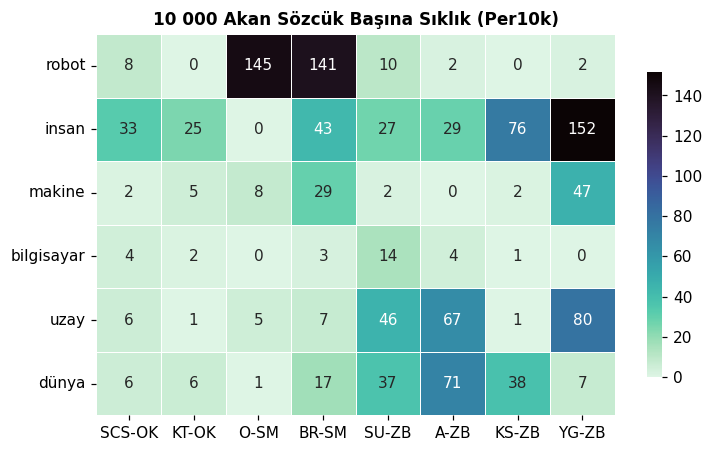

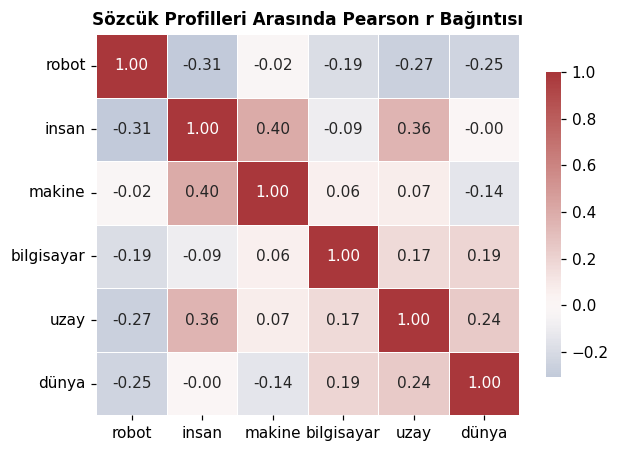

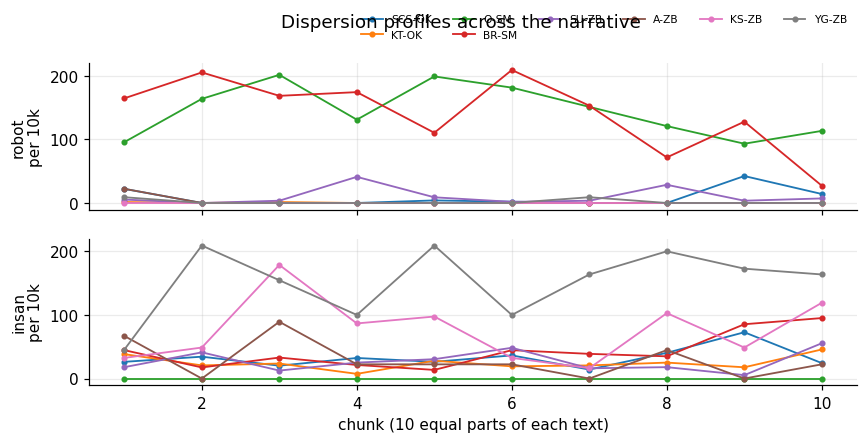

In [44]:
display(out.pairwise().round(3))
fig = viz.heatmap(out.rates, "10 000 Akan Sözcük Başına Sıklık (Per10k)", fmt=".0f"); plt.show()
fig = viz.heatmap(out.matrix("pearson_r"), "Sözcük Profilleri Arasında Pearson r Bağıntısı", cmap="vlag",
                  center=0, fmt=".2f"); plt.show()
fig = viz.chunk_dispersion({k: out.chunks[k] for k in ["robot", "insan"]}, out.codes); plt.show()

**Adlandırılmış Gruplar** (Birleştirilmiş Anlamsal Alanlar) ve İçerik Sözcüğü Görünümü:

In [45]:
groups = {"makine alanı": ["robot", "makine", "bilgisayar"], "insan alanı": ["insan", "kişi", "adam"]}
g_raw = bk.analyze(groups, turkish, "lem")
g_con = bk.analyze(groups, turkish, "lem", filter_function_words=True, mode="drop")
display(g_raw.summary().round(3)); display(g_con.summary().round(3))
display(g_raw.pairwise().round(3))

,label,hits,per10k_pooled,texts_present,D_across_texts,D_within_text(mean)
0,makine alanı,1833,61.348,8,0.547,0.728
1,insan alanı,1916,64.126,8,0.743,0.848


,label,hits,per10k_pooled,texts_present,D_across_texts,D_within_text(mean)
0,makine alanı,1833,78.310,8,0.544,0.728
1,insan alanı,1916,81.856,8,0.747,0.845


,a,b,pearson_r,p_pearson,spearman_rho,p_spearman,cosine,q_pearson(BH),q_spearman(BH)
0,makine alanı,insan alanı,-0.166,0.14,-0.191,0.09,0.384,0.14,0.09


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Tek bir metnin dilimleri **içsel bağıntılıdır (otokorelasyon)**: buradaki p değerleri bir tarama aracıdır — bilimsel raporda öncelikle r / ρ / kosinüs ve D değerleri aktarılmalıdır.
- Bir metinde hiç geçmeyen bir sözcük tümüyle sıfırdan oluşan bir profil verir: Pearson/Spearman NaN, kosinüs ise 0 döndürür — bu beklenen matematiksel davranıştır, hata değildir.
- Çok kısa metinlerde (*The Light* gibi) 10 dilim her biri ~400 sözcüğe karşılık gelir; bu durumda D metriğinde gürültü artabilir.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** İngilizce kaynak metinlerde `robot`, `human`, `machine` sözcüklerinin yayılımını karşılaştırın.

<details><summary>Çözümü Göster</summary>

```python
bk.analyze(['robot', 'human', 'machine'], list(loader.load_all_english()), 'lem').summary()
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çevresel Türlerde Anlamsal Alanlar ve Sözcüksel Yayılım (Gries 2008; Juilland 1964):**
Yalnızca ham terim sıklığı, bir sözcüğün genel tür repertuarına mal olup olmadığını ya da
belirli bir sahneye sıkışıp kalmış bir anlık buluş mu olduğunu açıklayamaz. Juilland'ın $D$
katsayısı dağılımın türdeşliğini ölçerek, araştırmacının kanonlaşmış bilimkurgu terimlerini
(yüksek $D$) geçici veya yerel kullanımlardan ayırt etmesini sağlar.

</div>

---
# Bölüm 9 · Sözcüksel Zenginlik ve Çeşitlilik (LancsBox-X Ailesi)
⏱ ~35 dk · 📚 Önkoşullar: Bölüm 0–2

> Her yazarın sözvarlığı ne kadar zengin — metin boyundan bağımsız adil ölçüm.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Ham TTR oranının neden farklı uzunluktaki metinleri karşılaştıramayacağını açıklayabilme
- 14'ten fazla sözcüksel çeşitlilik metriğini hesaplayabilme ve yorumlayabilme
- Radar grafiği, MATTR hareketli ortalama yörüngesi ve Zipf eğrilerini okuyabilme

### 9.1 Kuramsal Çerçeve: Metin Uzunluğu Sorunu
**TTR (Type-Token Ratio = Sözcük Türü / Sözcükbirim Oranı)**, bir metin uzadıkça kaçınılmaz olarak
*düşer*; çünkü eklenen her yeni sözcükbirimin daha önce geçmiş bir sözcüğün tekrarı olma olasılığı
artar (Heaps Yasası). Bu nedenle bir öykü ile kalın bir romanın ham TTR değerleri asla doğrudan
karşılaştırılamaz. Modern derlembilim, metin uzunluğundan (yaklaşık olarak) bağımsız metrikler
geliştirmiştir: **STTR** (1000 sözcüklük standart blokların ortalama TTR'si), **MATTR** (kayan pencere
üzerinde hareketli ortalama TTR; Covington & McFall 2010), **MTLD** (McCarthy & Jarvis 2010) ve
**HD-D** (McCarthy & Jarvis 2007, 2010; hipergeometrik modelleme).
*LancsBox X* (Brezina, Weill-Tessier & McEnery 2021) yazılımının sunduğu bu zengin aileyi burada
sıfırdan uyguluyoruz:

| Metrik | Formül | Yüksek Değer Anlamı | Uzunluktan Bağımsız mı? |
|---|---|---|---|
| TTR | $V / N$ | Daha çeşitli | ❌ $N$ arttıkça çöker |
| Guiraud R | $V / \sqrt{N}$ | Daha çeşitli | ❌ Kısmen düzeltir |
| CTTR (Carroll) | $V / \sqrt{2N}$ | Daha çeşitli | ❌ Kısmen düzeltir |
| Herdan C | $\ln V / \ln N$ | Daha çeşitli | ❌ |
| Dugast U | $\ln^2 N / (\ln N - \ln V)$ | Daha çeşitli | ❌ |
| Maas a² | $(\ln N - \ln V) / \ln^2 N$ | **Daha az** çeşitli | ❌ |
| Yule K | $10^4 (\sum m^2 V_m - N) / N^2$ | **Daha az** çeşitli (tekrarlayıcı) | ✅ Evet |
| Simpson D | $\sum n(n-1) / (N(N-1))$ | **Daha az** çeşitli | ✅ Evet |
| Honoré R | $100 \ln N / (1 - V_1/V)$ | Daha zengin sözvarlığı | ❌ |
| Hapax % | $V_1 / V$, $V_1 / N$ | Tek seferlik sözcük çokluğu | ❌ |
| STTR (L=1000) | 1000 sözcüklük blokların ortalama TTR'si | Daha çeşitli | ✅ Evet |
| MATTR (w=100) | Kayan pencere ortalama TTR'si | Daha çeşitli | ✅ Evet |
| MTLD | Ortalama faktör uzunluğu (TTR $\le 0.72$), ileri/geri ortalaması | Daha çeşitli | ✅ Evet |
| HD-D | $\sum (1 - C(N-f, 42)/C(N, 42)) / 42$ (hipergeometrik çekim) | Daha çeşitli | ✅ Evet |

### 9.2 Elle Doğrulanabilir Oyuncak Örnek
Sözcükler: `the cat saw the dog the dog saw the cat` ($N = 10$): sözcük türleri {the: 4, cat: 2, dog: 2, saw: 2}
$\Rightarrow V = 4$, $\text{TTR} = 0.4$, $\text{Guiraud} = 4 / \sqrt{10} = 1.26$,
$\text{Yule K} = 10^4(16 + 3 \cdot 4 - 10) / 100 = \mathbf{1800}$,
$\text{Simpson D} = (12 + 2 + 2 + 2) / 90 = \mathbf{0.2}$ — tümü `tests/test_corpus_toolkit.py` içinde doğrulanmıştır.

### 📋 Komut ve İşlev Kılavuzu · Çeşitlilik Yöntemleri ve Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `diversity.diversity_metrics(forms)` | 14+ LancsBox-X metriğinin tümünü sözlük olarak döndürür | `diversity.diversity_metrics(forms)` |
| `diversity.mattr(forms, window=100)` | Kayan pencere boyunca hareketli ortalama TTR | `diversity.mattr(forms, 100)` |
| `diversity.mtld(forms, threshold=0.72)` | İleri ve geri MTLD geçişlerinin ortalaması | `diversity.mtld(forms)` |
| `diversity.hdd(forms, sample_size=42)` | Hipergeometrik HD-D örnekleme beklentisi | `diversity.hdd(forms)` |
| `analysis.diversity_for(loader, texts, field='lem')` | Birden fazla metin için önbellekli özet tablosu | `analysis.diversity_for(loader, texts)` |

#### 9.3 Metin Uzunluğu Sorununu Kendi Gözlerinizle Görün

Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)


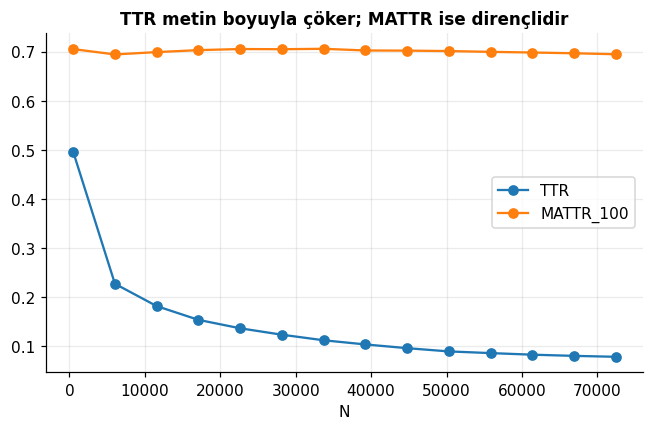

N,500,6033,11566,17099,22632,28165,33698,39231,44764,50297,55830,61363,66896,72429
TTR,0.496,0.227,0.182,0.154,0.137,0.124,0.112,0.104,0.096,0.090,0.086,0.083,0.080,0.079
MATTR_100,0.705,0.694,0.699,0.703,0.705,0.705,0.706,0.702,0.702,0.701,0.700,0.698,0.697,0.695
MTLD,85.501,74.669,78.875,81.967,82.811,82.562,83.051,80.887,80.561,79.821,78.665,77.991,77.134,76.013


In [46]:
text = loader.load_text("IR-IA")
print(loader.registry.display(text))
forms = TokenView(text, "lem", False).analysed()
sizes = np.unique(np.linspace(500, len(forms), 14).astype(int))
rows = [{"N": n, "TTR": diversity.ttr(forms[:n]),
         "MATTR_100": diversity.mattr(forms[:n], 100), "MTLD": diversity.mtld(forms[:n])}
        for n in sizes]
df = pd.DataFrame(rows).set_index("N")
ax = df[["TTR", "MATTR_100"]].plot(marker="o", figsize=(7, 4), title="TTR metin boyuyla çöker; MATTR ise dirençlidir")
plt.show(); display(df.round(3).T)
text.evict()

#### 9.4 13 Metnin Çeşitlilik Profili (Sözlükbirimler, Ham Görünüm) — İlk çalıştırmadan sonra önbelleklenir

In [47]:
div_raw = analysis.diversity_for(loader, loader.load_all(), field="lem", filter_function_words=False)
show_table(div_raw.round(3), page_size=20, title="Sözcüksel Çeşitlilik (13 Metin — Ham Sözlükbirimler)")

index⇅,N⇅,V⇅,TTR⇅,Guiraud_R⇅,CTTR⇅,Herdan_C⇅,Dugast_U⇅,Maas_a2⇅,Yule_K⇅,Simpson_D⇅,Honore_R⇅,Hapax_types_pct⇅,Hapax_tokens_pct⇅,STTR⇅,MATTR_50⇅,MATTR_100⇅,MATTR_500⇅,MTLD⇅,HD_D⇅
SCS-OK · Son Cephede Şafak,"49,563.000","3,399.000",0.069,15.268,10.796,0.752,43.615,0.023,43.221,0.004,"1,626.675",33.539,2.300,0.451,0.877,0.799,0.560,166.349,0.927
ASD-PKD · A Scanner Darkly,"87,994.000","5,928.000",0.067,19.984,14.131,0.763,48.050,0.021,87.622,0.009,"1,967.651",42.139,2.839,0.375,0.788,0.688,0.458,71.999,0.865
KT-OK · Karanlığı Taramak,"67,933.000","4,557.000",0.067,17.484,12.363,0.757,45.818,0.022,53.552,0.005,"1,802.433",38.271,2.567,0.432,0.841,0.756,0.530,118.657,0.913
"O-SM · OBİ,J.S.927","39,695.000","2,174.000",0.055,10.912,7.716,0.726,38.602,0.026,48.050,0.005,"1,562.827",32.245,1.766,0.401,0.862,0.773,0.517,133.171,0.918
"IR-IA · I, Robot","72,429.000","5,691.000",0.079,21.146,14.953,0.773,49.229,0.020,95.629,0.010,"2,040.511",45.159,3.548,0.390,0.792,0.695,0.472,76.013,0.858
"BR-SM · Ben, Robot: Mekanik Adam Devri","51,632.000","3,658.000",0.071,16.098,11.383,0.756,44.486,0.022,48.533,0.005,"1,680.620",35.429,2.510,0.445,0.858,0.778,0.549,141.488,0.921
SU-ZB · Sahte Uygarlık,"55,953.000","4,172.000",0.075,17.637,12.471,0.763,46.036,0.022,43.948,0.004,"1,665.793",34.372,2.563,0.476,0.859,0.782,0.574,156.330,0.929
SP-JL · The Scarlet Plague,"20,596.000","2,655.000",0.129,18.500,13.082,0.794,48.159,0.021,132.838,0.013,"1,976.891",49.755,6.414,0.366,0.755,0.656,0.446,57.540,0.829
TL-PA · The Light,"4,367.000","1,098.000",0.251,16.615,11.749,0.835,50.888,0.020,119.027,0.012,"2,160.388",61.202,15.388,0.404,0.809,0.714,0.499,89.942,0.836
TLP-ML · The Lonely Planet,"11,517.000","1,788.000",0.155,16.661,11.781,0.801,46.948,0.021,130.549,0.013,"1,815.486",48.490,7.528,0.375,0.766,0.664,0.451,62.065,0.827


In [48]:
div_con = analysis.diversity_for(loader, loader.load_all(), field="lem", filter_function_words=True)
show_table(div_con[["N", "V", "TTR", "STTR", "MATTR_100", "MTLD", "HD_D", "Yule_K", "Hapax_types_pct"]].round(3),
           page_size=20, title="Sözcüksel Çeşitlilik (İçerik Sözlükbirimleri)")

index⇅,N⇅,V⇅,TTR⇅,STTR⇅,MATTR_100⇅,MTLD⇅,HD_D⇅,Yule_K⇅,Hapax_types_pct⇅
SCS-OK · Son Cephede Şafak,"39,252.000","3,319.000",0.085,0.479,0.823,207.859,0.950,27.415,34.077
ASD-PKD · A Scanner Darkly,"44,088.000","5,772.000",0.131,0.523,0.789,149.044,0.953,26.529,42.949
KT-OK · Karanlığı Taramak,"51,449.000","4,467.000",0.087,0.475,0.784,143.908,0.944,31.471,38.863
"O-SM · OBİ,J.S.927","30,966.000","2,103.000",0.068,0.419,0.788,146.226,0.937,34.090,33.191
"IR-IA · I, Robot","36,349.000","5,541.000",0.152,0.546,0.824,218.936,0.962,19.942,45.948
"BR-SM · Ben, Robot: Mekanik Adam Devri","40,115.000","3,579.000",0.089,0.479,0.805,178.270,0.950,27.384,35.960
SU-ZB · Sahte Uygarlık,"45,638.000","4,085.000",0.090,0.508,0.812,202.515,0.961,20.495,34.884
SP-JL · The Scarlet Plague,"10,038.000","2,538.000",0.253,0.526,0.809,157.579,0.961,20.593,51.576
TL-PA · The Light,"2,070.000","1,001.000",0.484,0.585,0.888,420.751,0.958,22.423,65.934
TLP-ML · The Lonely Planet,"6,039.000","1,698.000",0.281,0.509,0.781,153.112,0.932,43.226,50.824


In [49]:
# Yüzey sözcük (token) ve sözlükbirim (lemma) çeşitliliği: Sondan eklemelilik Türkçede token türlerini şişirir
div_tok = analysis.diversity_for(loader, loader.load_all_turkish(), field="tok")
cmp = pd.DataFrame({"MATTR_100 (tokens)": div_tok["MATTR_100"],
                    "MATTR_100 (lemmas)": div_raw.loc[div_tok.index, "MATTR_100"]})
display(cmp.round(3))

,MATTR_100 (tokens),MATTR_100 (lemmas)
SCS-OK · Son Cephede Şafak,0.904,0.799
KT-OK · Karanlığı Taramak,0.867,0.756
"O-SM · OBİ,J.S.927",0.878,0.773
"BR-SM · Ben, Robot: Mekanik Adam Devri",0.880,0.778
SU-ZB · Sahte Uygarlık,0.878,0.782
A-ZB · Kıyametten Sonra: Aydınlık,0.868,0.767
KS-ZB · Kıyametten Sonra: Kıyametten Sonra,0.857,0.750
YG-ZB · Kıyametten Sonra: Yalnız Gezegen,0.841,0.715


In [50]:
# Noktalama kiplerinin çeşitliliğe etkisi: drop (standart) vs strip (birleştir) vs split (ayrıştır)
t_samples = [loader.load_text("BR-SM"), loader.load_text("KT-OK")]
div_p_drop = analysis.diversity_for(loader, t_samples, field="tok", punct="drop")
div_p_strip = analysis.diversity_for(loader, t_samples, field="tok", punct="strip")
div_p_split = analysis.diversity_for(loader, t_samples, field="tok", punct="split")
p_comp = pd.DataFrame({
    "N (drop)": div_p_drop["N"], "V (drop)": div_p_drop["V"],
    "N (strip)": div_p_strip["N"], "V (strip)": div_p_strip["V"],
    "N (split)": div_p_split["N"], "V (split)": div_p_split["V"],
})
display(p_comp)
for s in t_samples: s.evict()

,N (drop),V (drop),N (strip),V (strip),N (split),V (split)
"BR-SM · Ben, Robot: Mekanik Adam Devri",51632.0,14583.0,51610.0,14517.0,52743.0,14304.0
KT-OK · Karanlığı Taramak,67933.0,17452.0,67763.0,17427.0,68815.0,17217.0


#### 9.5 Çeşitlilik Şekilleri: Radar Grafiği, MATTR Yörüngesi ve Zipf Eğrisi

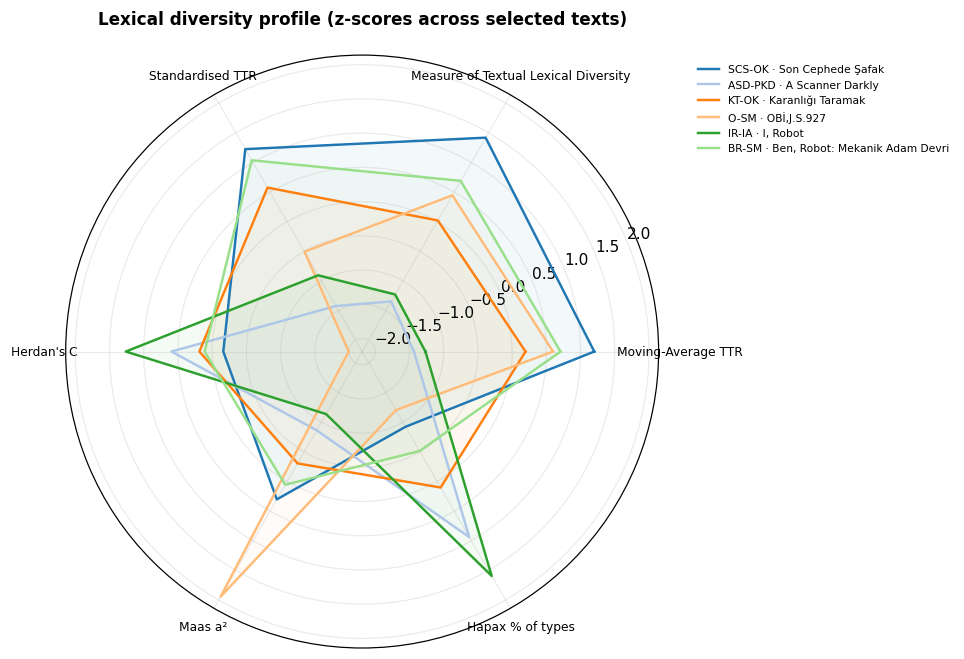

Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
Selma Mine — OBİ,J.S.927 [O-SM] (1980, Turkish indigenous)


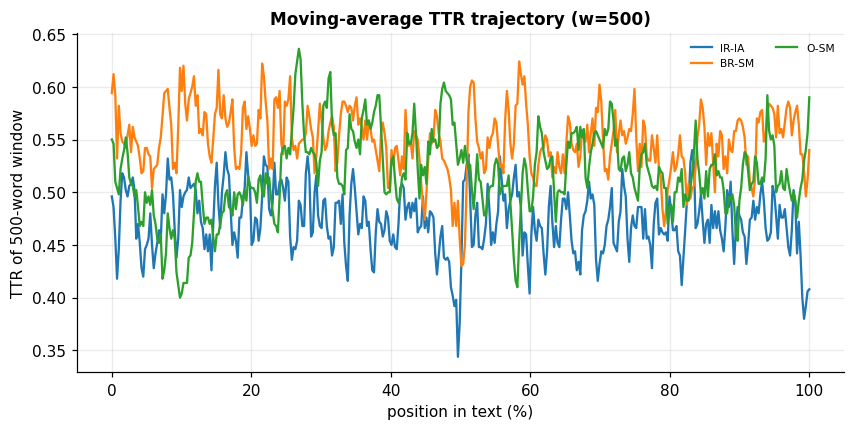

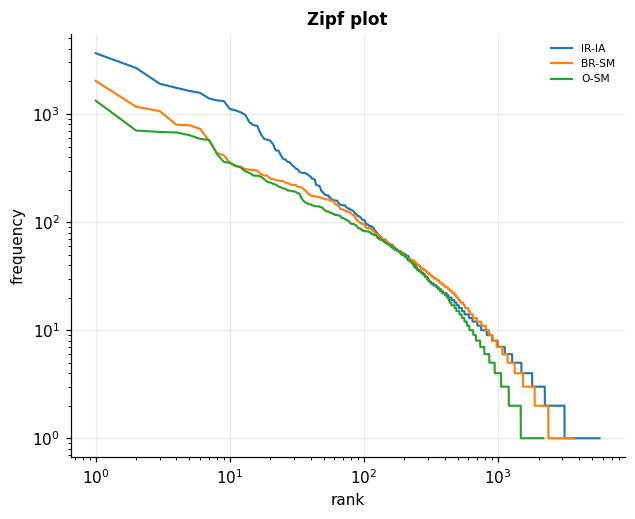

In [51]:
fig = viz.diversity_radar(div_raw.loc[[i for i in div_raw.index if i.split(' · ')[0] in
                                       ('IR-IA','BR-SM','O-SM','ASD-PKD','KT-OK','SCS-OK')]]); plt.show()
sel = [loader.load_text(c) for c in ("IR-IA", "BR-SM", "O-SM")]
for s in sel: print(loader.registry.display(s))
traj = analysis.mattr_trajectories_for(sel, window=500)
fig = viz.mattr_trajectories(traj, 500); plt.show()
fig = viz.zipf_plot(analysis.zipf_for(sel)); plt.show()
for s in sel: s.evict()

<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- `STTR` metriği $N < 1000$ olduğunda bir uyarı vererek TTR değerine geri döner; benzer şekilde `MATTR` $N < w$ durumunda TTR'ye döner. *The Light* metni (~4 000 sözcük) sınırdadır; dikkatle değerlendirilmelidir.
- Dugast ve Honoré metrikleri, $V = N$ veya $V_1 = V$ olduğunda tanımsız (NaN) kalır.
- Karşılaştırma yaparken her zaman **sözlükbirim ile sözlükbirimi**, **ham görünüm ile ham görünümü** eşleştirin.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Hangi yerli bilimkurgu romanı en yüksek MTLD değerine sahiptir (sözlükbirimler, içerik görünümü)?

<details><summary>Çözümü Göster</summary>

```python
d = div_con.reset_index()
d[d['index'].str.startswith(('SCS-OK', 'O-SM', 'SU-ZB'))].nlargest(1, 'MTLD')
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Çeviri Dili Sadeleşmesi ve Sözcüksel Repertuar (Baker 1993; Toury 2012):**
Aynı yazar-çevirmenin *yerli telif* yapıtlarında, *çeviri* yapıtlarına kıyasla daha yüksek
çeşitlilik gözlenmesi, çeviribilim literatüründeki **normalleşme / standartlaşma** evrenseliyle
(Baker 1993) uyumludur. Bununla birlikte çevirideki düşük çeşitlilik, kaynak metnin üslubundan da
(Asimov'un yalın ve denetimli sözvarlığı) kaynaklanabilir. Metrikler her zaman dizin satırlarıyla
birlikte okunmalıdır.

</div>

---
# Bölüm 10 · Eşdizimlilik ve Birlikte Geçiş Ölçütleri
⏱ ~35 dk · 📚 Önkoşullar: Bölüm 6–7

> Hangi sözcükler düğüm sözcükle tesadüfün ötesinde anlamlı bir sıklıkla bir araya gelmektedir?

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Düğüm ve eşdizimli sözcük için 2×2'lik olasılık tablosunu (contingency table) oluşturabilme
- MI, MI², MI³, T-skoru, olabilirlik oranı (G²) ve Log-Dice ölçütlerini elle hesaplayabilme
- Çekim gücü ile istatistiksel kanıtı ayırt edebilme (GraphColl dağılım grafiği)
- Birleşimli aralık yuva sayımı (union-slot) ile ikili birlikte geçiş farkını kavrama

### 10.1 Kuramsal Çerçeve
J. R. Firth'ün (1957) ünlü ilkesi: *“Bir sözcüğü, birlikte arkadaşlık ettiği sözcüklerden tanırsınız.”*
Bir **düğüm sözcük (node)** ve bir aralık penceresi (sol $L$, sağ $R$) belirleyelim:

- $N$: Metindeki / derlemdeki toplam akan sözcük sayısı,
- $R_1$: Pencere **yuvaları** (düğüm pencerelerinin kapsadığı toplam konumlar, düğümün kendisi hariç).
  Araç setimizde çakışan pencereler her konumu **bir kez** sayar (birleşimli yuvalar / union slots).
  Bu yöntem iki yakın düğümün arasındaki sözcükleri çift saymaz ve $O_{11} \le R_1$ ile $O_{11} \le C_1$ güvencesi verir.
- $C_1$: Aday eşdizimli sözcüğün tüm metindeki toplam sıklığı,
- $O_{11}$: Aday sözcüğün düğüm penceresi yuvaları *içinde* gözlenen sıklığı ($O = \text{observed}$),
- $E_{11} = \frac{R_1 \cdot C_1}{N}$: Bağımsız rastgele dağılım varsayımı altında beklenen birlikte geçiş sayısı ($E = \text{expected}$),

$2 \times 2$ olasılık tablosu şu şekilde kurulur:

| | Pencere İçinde ($W$) | Pencere Dışında ($\neg W$) | Toplam |
|---|---|---|---|
| **Aday Sözcük ($C$)** | $O_{11}$ | $O_{12} = C_1 - O_{11}$ | $C_1$ |
| **Diğer Sözcükler ($\neg C$)** | $O_{21} = R_1 - O_{11}$ | $O_{22} = N - R_1 - C_1 + O_{11}$ | $N - C_1$ |
| **Toplam** | $R_1$ | $N - R_1$ | $N$ |

Standart eşdizim ve bağıntı ölçütleri:

| Ölçüt | Formül | Özellikler ve Tercih Eğilimi |
|---|---|---|
| **MI** (Church & Hanks 1990) | $\log_2 \frac{O_{11}}{E_{11}}$ | Birliktelik gücü (etki büyüklüğü); düşük sıklıklı nadir sözcüklere aşırı duyarlıdır |
| **MI²** (Daille 1994) | $\log_2 \frac{O_{11}^2}{E_{11}}$ | Düşük sıklık yanlılığını dengeler |
| **MI³** (Daille 1994) | $\log_2 \frac{O_{11}^3}{E_{11}}$ | Sık tekrarlanan güçlü kalıpları öne çıkarır |
| **T-skoru** (Church vd. 1991) | $\frac{O_{11} - E_{11}}{\sqrt{O_{11}}}$ | İstatistiksel kesinlik/kanıt; sık geçen dilbilgisel ortakları öne çıkarır |
| **G²** (Dunning 1993) | $2 \sum_{i,j} O_{ij} \ln \frac{O_{ij}}{E_{ij}}$ | İşaretli olabilirlik oranı testi; pozitif = çekim, negatif = itim |
| **Log-Dice** (Rychlý 2008) | $14 + \log_2 \frac{2 O_{11}}{f_{\text{düğüm}} + C_1}$ | Derlem boyutundan bütünüyle bağımsızdır; kusursuz eşdizim için en çok 14 değerini alır |

**Güç ile Kanıtın Ayrıştırılması (GraphColl Yaklaşımı, Brezina vd. 2015).**
MI metriği *etki büyüklüğünü (gücü)* ölçerken, $G^2$ metriği *örneklem büyüklüğüne dayalı istatistiksel kanıtı*
(kesinliği) ölçer. MI ve $G^2$ değerlerini iki eksende gösteren bir dağılım grafiği dört ana bölgeyi ortaya koyar:
nadir özel birliktelikler (yüksek MI, düşük $G^2$), merkezi izleksel eşdizimler (yüksek MI, yüksek $G^2$),
dilbilgisel rutinler (düşük MI, yüksek $G^2$) ve rastgele gürültü.

### 10.2 Elle Doğrulanabilir Oyuncak Örnek
Verilenler: $N = 1000$, $R_1 = 100$, $C_1 = 20$, $O_{11} = 10$, $f_{\text{düğüm}} = 50$:
1. $E_{11} = \frac{100 \times 20}{1000} = 2.0$
2. $\text{MI} = \log_2(10 / 2) = \log_2(5) \approx 2.322$
3. $\text{MI}^2 = \log_2(100 / 2) = \log_2(50) \approx 5.644$
4. $\text{MI}^3 = \log_2(1000 / 2) = \log_2(500) \approx 8.966$
5. $\text{T-skoru} = \frac{10 - 2}{\sqrt{10}} = \frac{8}{3.1623} \approx 2.530$
6. $\text{Log-Dice} = 14 + \log_2 \left(\frac{20}{50 + 20}\right) = 14 + \log_2(0.2857) = 14 - 1.8074 \approx 12.193$

### 📋 Komut ve İşlev Kılavuzu · Eşdizim Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `collocation.association_table([o11], [c1], r1, n, f_node)` | Verilen sayımlar için 6 temel eşdizim ölçütünü hesaplama | `collocation.association_table([10], [20], 100, 1000, 50)` |
| `collocation.collocates(view, 'node', left=5, right=5, min_freq=5)` | G2/MI/LogDice değerlerine göre sıralanmış eşdizim tablosu çıkarma | `collocation.collocates(view, 'robot', 5, 5, min_freq=5, sort_by='G2')` |
| `viz.collocation_scatter(tab, 'node', x='MI', y='G2')` | Güç (MI) ve kanıt (G2) dağılım grafiğini çizdirme | `viz.collocation_scatter(tab, 'robot')` |
| `TokenView(text, 'lem', filter_function_words=True, mode='drop')` | İzleksel eşdizimler için içerik sözcüğü görünümü | `TokenView(text, 'lem', True, 'drop')` |
| `nltk_adapter.nltk_collocations(view, n=10, min_freq=5)` | NLTK bigram eşdizim ölçütleriyle çapraz kontrol | `nltk_adapter.nltk_collocations(view)` |

In [52]:
# Elle doğrulanan oyuncak örnek kontrolü
toy = collocation.association_table([10], [20], r1=100, n=1000, f_node=50)
display(toy.round(3))

,O11,C1,E11,MI,MI2,MI3,T,G2,p_G2,LogDice
0,10,20,2.0,2.322,5.644,8.966,2.53,21.177,0.0,12.193


In [53]:
# Selma Mine'nin Ben, Robot çevirisinde 'robot' sözcüğü için eşdizimleri çıkarma
br = loader.load_text("BR-SM")
print("İncelenen metin:", loader.registry.display(br))
node_view = TokenView(br, "lem", False, "drop")
tab = collocation.collocates(node_view, "robot", left=5, right=5, min_freq=5, sort_by="G2")
print("Olasılık tablosu parametreleri:", tab.attrs)
show_table(tab.round(3), page_size=20, title="'robot' Eşdizimlileri — Ben, Robot (20 satır/sayfa, sıralanabilir)")

İncelenen metin: Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
Olasılık tablosu parametreleri: {'f_node': 729, 'N': 51632, 'R1': 4596, 'view': 'raw/lem', 'left': 5, 'right': 5, 'sentence_clamped': True}


collocate⇅,O11⇅,C1⇅,E11⇅,MI⇅,MI2⇅,MI3⇅,T⇅,G2⇅,p_G2⇅,LogDice⇅
d,45,48,4.273,3.397,8.889,14.380,6.071,196.219,0.000,10.890
b,43,50,4.451,3.272,8.698,14.125,5.879,169.195,0.000,10.821
merkez,38,45,4.006,3.246,8.494,13.742,5.515,146.522,0.000,10.652
firma,24,46,4.095,2.551,7.136,11.721,4.063,56.624,0.000,9.987
mekanik,17,31,2.759,2.623,6.711,10.798,3.454,42.219,0.000,9.518
tip,12,16,1.424,3.075,6.660,10.245,3.053,40.833,0.000,9.044
birleşik,16,33,2.937,2.445,6.445,10.445,3.266,34.900,0.000,9.426
altmış,12,20,1.780,2.753,6.338,9.923,2.950,32.651,0.000,9.036
kural,29,105,9.347,1.634,6.492,11.350,3.650,30.806,0.000,10.154
devlet,10,18,1.602,2.642,5.964,9.286,2.656,25.157,0.000,8.777


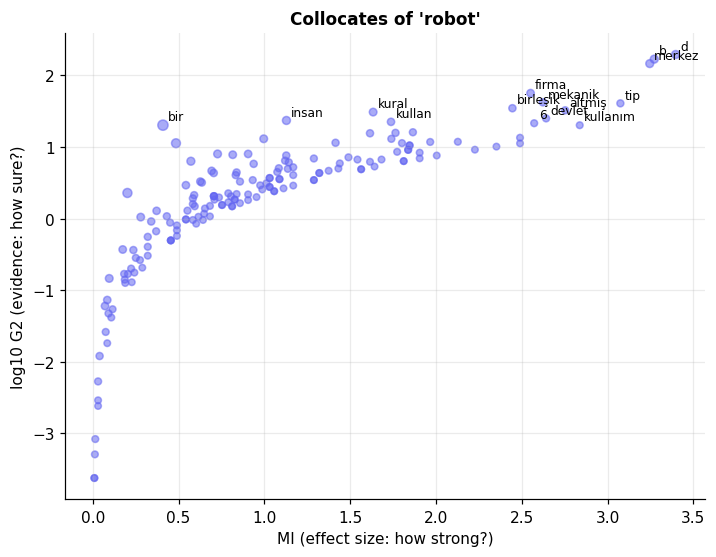

MI       → ['d', 'b', 'merkez', 'tip', 'kullanım', 'altmış', 'devlet', 'mekanik']
T        → ['d', 'b', 'merkez', 'firma', 'bir', 'kural', 'insan', 'mekanik']
LogDice  → ['bir', 've', 'ol', 'd', 'b', 'merkez', 'bu', 'insan']
G2       → ['d', 'b', 'merkez', 'firma', 'mekanik', 'tip', 'birleşik', 'altmış']


In [54]:
# GraphColl tarzı güç (MI) vs kanıt (G2) dağılım grafiği
fig = viz.collocation_scatter(tab, "robot", x="MI", y="G2")
plt.show()

# Farklı ölçütlere göre en üst sırada yer alan eşdizimli ortakları karşılaştırma
for measure in ("MI", "T", "LogDice", "G2"):
    top_words = tab.sort_values(measure, ascending=False)["collocate"].head(8).tolist()
    print(f"{measure:8s} → {top_words}")

#### Pencere Genişliği, Sınır Kenetlenmesi ve İçerik Sözcüğü Görünümü
Pencere aralığı doğrudan *araştırma sorusuna* bağlıdır:
- Dar pencereler ($\pm 1, \pm 2$) **biçimsözdizimsel** yapıyı ve yakın yönetimi (ilgeçler, yardımcı eylemler, niteleyiciler) yakalar.
- Geniş pencereler ($\pm 5, \pm 10$) **izleksel/söylemsel** birliktelikleri ortaya çıkarır.
- İşlevsel sözcükler filtrelendiğinde **`drop`** mesafeyi *içerik sözcükleri* üzerinden ölçer; **`mask`** ise akan sözcük konumlarını korur.

In [55]:
def top_collocates(view, left, right, sort_by="G2"):
    res = collocation.collocates(view, "robot", left=left, right=right, min_freq=5, sort_by=sort_by)
    return res["collocate"].head(8).tolist()

print("Ham pencere ±2    :", top_collocates(TokenView(br, "lem", False), 2, 2))
print("Ham pencere ±10   :", top_collocates(TokenView(br, "lem", False), 10, 10))
print("İçerik 'drop'     :", top_collocates(TokenView(br, "lem", True, "drop"), 5, 5))
print("İçerik 'mask'     :", top_collocates(TokenView(br, "lem", True, "mask"), 5, 5))

Ham pencere ±2    : ['d', 'b', 'merkez', 'mekanik', 'birleşik', 'bir', 'altmış', 'devlet']
Ham pencere ±10   : ['d', 'b', 'merkez', 'firma', 'altmış', 'tip', 'mekanik', 'insan']
İçerik 'drop'     : ['d', 'b', 'merkez', 'firma', 'mekanik', 'tip', 'kural', 'birleşik']
İçerik 'mask'     : ['d', 'b', 'merkez', 'firma', 'mekanik', 'tip', 'birleşik', 'altmış']


#### NLTK ile Çapraz Kontrol: Bitişik İkili (Bigram) Eşdizimleri

In [56]:
display(nltk_adapter.nltk_collocations(TokenView(br, "lem", True), n=10, min_freq=5, measure="likelihood_ratio"))
display(nltk_adapter.top_ngrams(TokenView(br, "lem", True), n=2, top=8))
br.evict()

,bigram,likelihood_ratio
0,b d,580.215707
1,sus calvin,577.324246
2,dr calvin,356.722877
3,birinci kural,343.636718
4,nestor 10,319.862533
5,d robot,303.119087
6,temel kural,285.527954
7,gamma ışın,276.699032
8,devam et,275.711823
9,ayak kalk,269.420611


,ngram,freq
0,sus calvin,66
1,b d,42
2,d robot,42
3,dr calvin,41
4,söz et,40
5,karşı ver,37
6,birinci kural,34
7,de powell,34


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Karakter özel adları (*Susan Calvin*, *Mike Donovan*) ham eşdizim listelerini domine edebilir: izleksel sözvarlığını görmek için özel adları filtreleyin (`exclude_pos={'PROPN'}`).
- Pencere yuvaları her konum için bir kez sayılır (union slots): bu kural çakışan pencerelerin aynı sözcüğü mükerrer saymasını önler ve $O_{11} \le C_1$ tutarlılığını sağlar.
- $G^2$ istatistiği işaretlidir: negatif değerler itimi (sözcüklerin tesadüfen beklenenden *daha az* sıklıkla bir araya geldiğini) gösterir.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Isaac Asimov'un *I, Robot* romanında `human` (insan) sözlükbirimi ile Log-Dice değerine göre en güçlü eşdizim oluşturan İngilizce sözcükler hangileridir (±4)?

<details><summary>Çözümü Göster</summary>

```python
ir = loader.load_text('IR-IA')
print(loader.registry.display(ir))
v = TokenView(ir, 'lem', True)
display(collocation.collocates(v, 'human', 4, 4, min_freq=3, sort_by='LogDice').head(10))
ir.evict()
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Firthçi Anlambilim ve Repertuar Modellemesi (Firth 1957; Sinclair 1991):**
Çoğuldizge kuramında (Even-Zohar 1990), eşdizimsel profiller çeviri metinlerin yabancı sözcük
öbeklerini (*kalklar*, örn. *pozitronik beyin*) erek edebiyata aktarıp aktarmadığını ya da yerli
dilsel kalıplara uyarlayıp uyarlamadığını belgeler. Log-Dice (Rychlý 2008), toplam derlem
boyutundan etkilenmediği için farklı uzunluktaki yazar-çevirmen yapıtlarını karşılaştırmak adına
en güvenilir ölçüttür.

</div>

---
# Bölüm 11 · TF-IDF ve Ayırt Edici Sözvarlığı (Keyness)
⏱ ~20 dk · 📚 Önkoşullar: Bölüm 0–2

> Derlemdeki her metni diğerlerinden en çok ayıran özgün sözcükler hangileridir?

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- TF-IDF ağırlıklarını elle hesaplayabilme ve scikit-learn ile birebir eşleştiğini doğrulayabilme
- İngilizce ve Türkçe alt derlemleri kuramsal gereklilikle ayrı ayrı eğitebilme
- Ayırt edicilik ısı haritalarını okuyabilme ve özel adları eleyerek tür sözvarlığını ortaya çıkarabilme

### 11.1 Kuramsal Çerçeve
TF-IDF (Spärck Jones 1972), sözcükleri metin içi sıklıkları (**TF**) ile metinlerarası ayırt ediciliklerinin
(**IDF**) çarpımıyla ağırlıklandırır. Scikit-learn kütüphanesiyle birebir eşleşen algoritmamız şu bileşenleri kullanır:

- **Alt-doğrusal TF**: $\text{count} > 0$ için $\text{TF}(t, d) = 1 + \ln(\text{count}(t, d))$ (tekrarların azalan marjinal etkisi).
- **Düzeltilmiş (Smooth) IDF**: $\text{IDF}(t) = \ln\left(\frac{1 + N}{1 + \text{DF}(t)}\right) + 1$; burada $N$ toplam metin sayısı, $\text{DF}(t)$ ise terimin geçtiği metin sayısıdır.
- **L2 Normu**: $\vec{v}_{\text{norm}} = \frac{\vec{v}}{\|\vec{v}\|_2}$ metin uzunluğunun anahtarlık ağırlıklarını çarpıtmasını önler.

İngilizce ve Türkçe kökten farklı dilbilgisel ve biçimbilimsel yapılara sahip olduğundan, iki dil **ayrı alt derlemler**
olarak modellenir.

### 11.2 Elle Doğrulanabilir Oyuncak Örnek — Elle Hesaplama vs scikit-learn
Üç belge: $d_1 = [a, b, b]$, $d_2 = [a, c]$, $d_3 = [c, c, d]$ ($N = 3$).
- $a$: $d_1, d_2$ belgelerinde geçer $\Rightarrow \text{DF} = 2 \Rightarrow \text{IDF} = \ln(4/3) + 1 \approx 1.2877$
- $b$: $d_1$ belgesinde geçer $\Rightarrow \text{DF} = 1 \Rightarrow \text{IDF} = \ln(4/2) + 1 = \ln(2) + 1 \approx 1.6931$
- $c$: $d_2, d_3$ belgelerinde geçer $\Rightarrow \text{DF} = 2 \Rightarrow \text{IDF} = \ln(4/3) + 1 \approx 1.2877$
- $d$: $d_3$ belgesinde geçer $\Rightarrow \text{DF} = 1 \Rightarrow \text{IDF} = \ln(4/2) + 1 = \ln(2) + 1 \approx 1.6931$

$d_1$ içinde: $\text{tf}(a) = 1 + \ln(1) = 1.0$; $\text{tf}(b) = 1 + \ln(2) \approx 1.6931$.
Norm öncesi ağırlıklar: $w(a) = 1.0 \times 1.2877 = 1.2877$; $w(b) = 1.6931 \times 1.6931 \approx 2.8667$.
L2 normu: $\sqrt{1.2877^2 + 2.8667^2} = \sqrt{1.6582 + 8.2180} = 3.1427$.
Normalize $d_1$: $a \approx 0.410$, $b \approx 0.912$.

### 📋 Komut ve İşlev Kılavuzu · TF-IDF Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `tfidf.tfidf_manual(docs)` | Belge listelerinden alt-doğrusal düzeltilmiş TF-IDF tablosu üretme | `tfidf.tfidf_manual([['a', 'b'], ['b', 'c']])` |
| `tfidf.TfidfAnalyzer()` | Derlem TF-IDF çözümleyicisini başlatma | `analyzer = tfidf.TfidfAnalyzer()` |
| `analyzer.fit(texts, field='lem', filter_function_words=True)` | Alt derlemi eğiterek ayırt edicilik vektörlerini çıkarma | `res = analyzer.fit(texts, 'lem', True)` |
| `res.top_terms(doc_id, n=10)` | Belirli bir metin için en ayırt edici n terimi listeleme | `res.top_terms('BR-SM', 10)` |
| `res.dense_top(top_k=5)` | Tüm belgeler boyunca en üstün terimlerin yoğun matrisini üretme | `res.dense_top(5)` |
| `viz.heatmap(df, title)` | Metinler arası anahtarlık ısı haritasını çizdirme | `viz.heatmap(matrix, 'Keyness')` |

In [57]:
# Elle hesaplama ile scikit-learn çıktısının birebir eşleşme testi
docs = [["a", "b", "b"], ["a", "c"], ["c", "c", "d"]]
manual = tfidf.tfidf_manual(docs)
display(manual.round(3))

from sklearn.feature_extraction.text import TfidfVectorizer
skl = TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True).fit_transform(docs).toarray()
print("scikit-learn ile birebir esitlik:", np.allclose(skl, manual[sorted(manual.columns)].to_numpy()))

,a,b,c,d
0,0.410,0.912,0.000,0.000
1,0.707,0.000,0.707,0.000
2,0.000,0.000,0.790,0.613


scikit-learn ile birebir esitlik: True


In [58]:
# İngilizce ve Türkçe alt derlemleri ayrı ayrı çözümleme
T = tfidf.TfidfAnalyzer()
en = T.fit(loader.load_all_english(), "lem", filter_function_words=True)
tr = T.fit(loader.load_all_turkish(), "lem", filter_function_words=True)

print("--- En Ayırt Edici İngilizce Sözlükbirimler ---")
for d in en.doc_ids[:3]:
    full_title = loader.registry.title_of(d)
    print(f"{d} ({full_title}): {en.top_terms(d, 6)['term'].tolist()}")

print()
print("--- En Ayırt Edici Türkçe Sözlükbirimler ---")
for d in tr.doc_ids[:3]:
    full_title = loader.registry.title_of(d)
    print(f"{d} ({full_title}): {tr.top_terms(d, 6)['term'].tolist()}")

--- En Ayırt Edici İngilizce Sözlükbirimler ---
ASD-PKD (A Scanner Darkly): ['arctor', 'barris', 'fred', 'donna', 'luckman', 'bob']
IR-IA (I, Robot): ['powell', 'donovan', 'calvin', 'lanning', 'byerley', 'bogert']
SP-JL (The Scarlet Plague): ['hoo', 'edwin', 'germ', 'granser', 'hare', 'chauffeur']

--- En Ayırt Edici Türkçe Sözlükbirimler ---
SCS-OK (Son Cephede Şafak): ['ripley', 'jak', 'hicks', 'trevon', 'flingress', 'log']
KT-OK (Karanlığı Taramak): ['arctor', 'barris', 'fred', 'donna', 'luckman', 'bob']
O-SM (OBİ,J.S.927): ['obi', 'tura', 'körtix', 'x-2-xk', 'emnos', 'vazohi']


Görüldüğü üzere metindeki **karakter özel adları** (*Powell*, *Donovan*, *Arctor*) listelerin başında yer alır.
**İzleksel ve edebi sözvarlığını** ortaya çıkarmak için özel adlar elenir (`exclude_pos={'PROPN'}`):

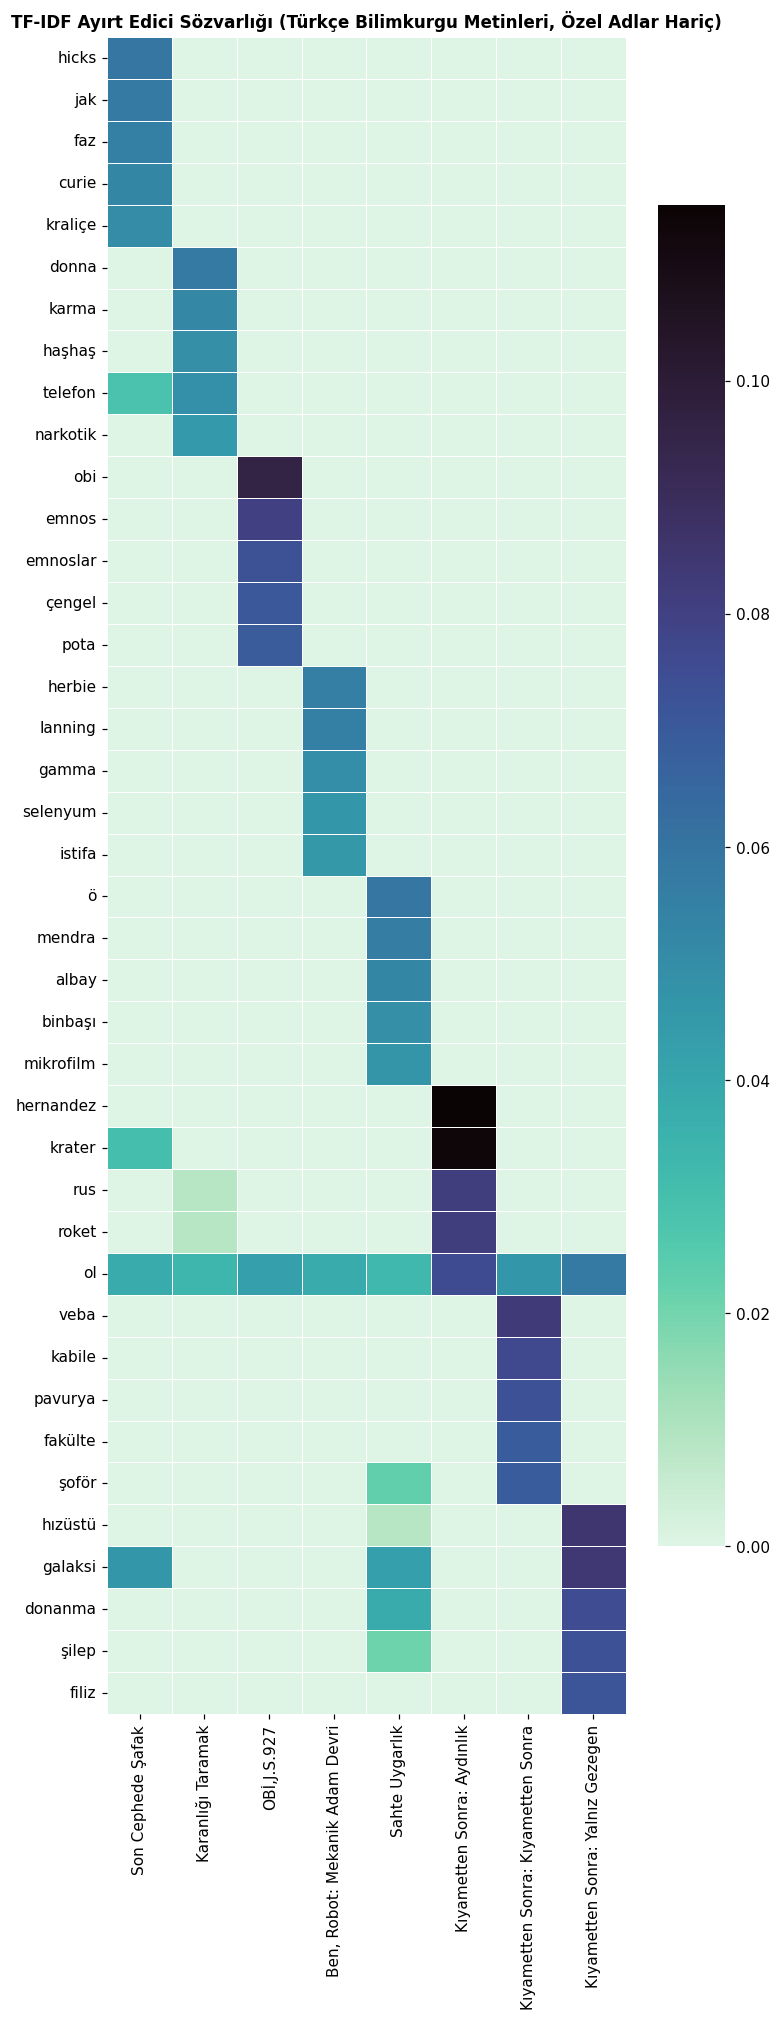

SCS-OK   (Son Cephede Şafak...) → ['hicks', 'jak', 'faz', 'curie', 'kraliçe', 'cornell']
KT-OK    (Karanlığı Taramak...) → ['donna', 'karma', 'haşhaş', 'telefon', 'narkotik', 'eroin']
O-SM     (OBİ,J.S.927...) → ['obi', 'emnos', 'emnoslar', 'çengel', 'pota', 'pil']
BR-SM    (Ben, Robot: Mekanik Adam Devri...) → ['herbie', 'lanning', 'gamma', 'selenyum', 'istifa', 'cemiyet']
SU-ZB    (Sahte Uygarlık...) → ['ö', 'mendra', 'albay', 'binbaşı', 'mikrofilm', 'gerilla']
A-ZB     (Kıyametten Sonra: Aydınlık...) → ['hernandez', 'krater', 'rus', 'roket', 'ol', 'ay']
KS-ZB    (Kıyametten Sonra: Kıyametten S...) → ['veba', 'kabile', 'pavurya', 'fakülte', 'şoför', 'midye']
YG-ZB    (Kıyametten Sonra: Yalnız Gezeg...) → ['hızüstü', 'galaksi', 'donanma', 'şilep', 'filiz', 'kargo']


In [59]:
tr_np = T.fit(loader.load_all_turkish(), "lem", filter_function_words=True, exclude_pos={"PROPN"})
fig = viz.heatmap(tr_np.dense_top(5).T, "TF-IDF Ayırt Edici Sözvarlığı (Türkçe Bilimkurgu Metinleri, Özel Adlar Hariç)",
                  cmap="mako_r", fmt=".2f", annotate=False)
plt.show()

for d in tr_np.doc_ids:
    print(f"{d:8s} ({loader.registry.title_of(d)[:30]}...) → {tr_np.top_terms(d, 6)['term'].tolist()}")

Az sayıda belgeden oluşan derlemlerde (5 İngilizce / 8 Türkçe metin) IDF değerleri kaba kalabilir.
Metinleri daha küçük parçalara dilimleyerek (`n_chunks=5`) daha geniş bir belge evreni benzetimi yapılabilir:

In [60]:
ch = T.fit(loader.load_all_turkish(), "lem", filter_function_words=True, n_chunks=5, exclude_pos={"PROPN"})
print(f"Toplam {len(ch.doc_ids)} adet dilimlenmiş sanal belge üretildi.")
print("BR-SM (Ben, Robot) ilk dilimi:", ch.top_terms("BR-SM#1", 6)["term"].tolist())

Toplam 40 adet dilimlenmiş sanal belge üretildi.
BR-SM (Ben, Robot) ilk dilimi: ['merkür', 'selenyum', 'atelye', 'robot', 'billur', 'hıçkırık']


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Her belgede geçen sözcükler $\text{IDF} \approx 1.0$ alır ve neredeyse sıfır anahtarlık ağırlığına sahip olur — bu tasarımın doğal sonucudur.
- TF-IDF keşifsel bir ağırlıklandırma yöntemidir, bir istatistiksel hipotez testi değildir: iki derlem arasında istatistiksel anlamlılık iddia ederken $G^2$ anahtarlık testini tercih edin.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Philip K. Dick'in *A Scanner Darkly* yapıtında geçen en ayırt edici 8 İngilizce sözlükbirim hangileridir (özel adlar hariç)?

<details><summary>Çözümü Göster</summary>

```python
r = T.fit(loader.load_all_english(), 'lem', True, exclude_pos={'PROPN'})
display(r.top_terms('ASD-PKD', 8))
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Derlem Biçembiliminde Anahtar Sözcük Çözümlemesi (Spärck Jones 1972; Scott 1997):**
Çeviribilimde anahtar sözcük profillemesi, yazarın biçemi ile çevirmenin alışkanlıklarını
(*habitus*, Simeoni 1998) ayırt etmeye olanak tanır. Özel adların ayıklanması, çeviri yoluyla
içe aktarılan *novum* (Suvin 1979) ve tekno-bilimsel sözvarlığını doğrudan gözler önüne serer.

</div>

---
# Bölüm 12 · Araştırma Raporlayıcısı ve Denetim İzi
⏱ ~15 dk · 📚 Önkoşullar: Bölüm 0–11

> Denetlenebilir ve yayına hazır araştırma raporları üretme.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Elde edilen tablo ve grafikleri tekrarlanabilir bir bilimsel raporda toplayabilme
- `data/corpus_analysis/…` dizini altındaki çıktıları denetleyebilme
- Üç-Düzeyli Kural (Three-Tier Rule) uyarınca verilere dayalı otomatik özetler üretebilme

### 12.1 Tekrarlanabilir Bilimsel Araştırma ve Çıktı Mimarisi
Dijital beşeri bilimler alanındaki her ampirik iddia, bağımsız araştırmacılarca denetlenebilir
bir veri akışına dayanmalıdır. `CorpusReporter`, tüm çıktıları sürüm kontrolü dışındaki özel dizinlerde
otomatik olarak yapılandırır:

```
data/corpus_analysis/
├── .cache/     Türetilmiş Parquet tabloları (atomik, sınırlı LRU önbellek)
├── reports/    <calisma_adi>_<zaman_damgasi>.md (+ biçimlendirilmiş Excel kitabı .xlsx)
├── tables/     Her analiz tablosu UTF-8 TSV olarak saklanır
└── figures/    Her görselleştirme 300-DPI yüksek çözünürlüklü PNG olarak kaydedilir
```

**Katı Veri-Kanıt Sözleşmesi (Data-Evidence Contract):** Raporlayıcının `top_bottom_summary`
işlevi, en uç istatistiksel değerleri doğrudan DataFrame matrislerinden hesaplar; asla varsayımsal
ya da dayanıksız yorumlar üretmez.

### 📋 Komut ve İşlev Kılavuzu · CorpusReporter Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `reporter.CorpusReporter(config, registry, run_name='...')` | Üstveri takipli rapor oturumu başlatma | `rep = reporter.CorpusReporter(loader.config, loader.registry, 'deneme')` |
| `rep.note(key=value)` | Yöntemsel parametreleri günlüğe kaydetme (pencere, görünüm vb.) | `rep.note(field='lem', span='phrase')` |
| `rep.add_section('Başlık', 'Açıklama')` | Açıklayıcı Markdown bölümü ekleme | `rep.add_section('POS Çözümlemesi', 'Genel bakış...')` |
| `rep.add_table('ad', df, caption='...')` | TSV tablosu kaydetme ve rapora + Excel'e ekleme | `rep.add_table('diversity', df, caption='Tablo 1')` |
| `rep.add_figure('ad', fig, caption='...')` | 300-DPI PNG kaydetme ve rapora bağlama | `rep.add_figure('radar', fig, caption='Şekil 1')` |
| `rep.add_summary(reporter.top_bottom_summary(df, col, id_col))` | Veriye dayalı matematiksel özet ekleme | `rep.add_summary(reporter.top_bottom_summary(df, 'MTLD', 'pair'))` |
| `rep.finalize()` | Markdown raporu ve çok sayfalı Excel kitabını derleme | `rapor_yolu = rep.finalize()` |
| `analysis.standard_report(loader, run_name='...')` | Tek satırda standart boru hattı raporu (Envanter, Hizalama, POS, Çeşitlilik) | `analysis.standard_report(loader, 'standart')` |

Rapor oluşturuldu: /home/ben/Documents/thesis/data/corpus_analysis/reports/not_defteri_ornek_20261024_145453.md


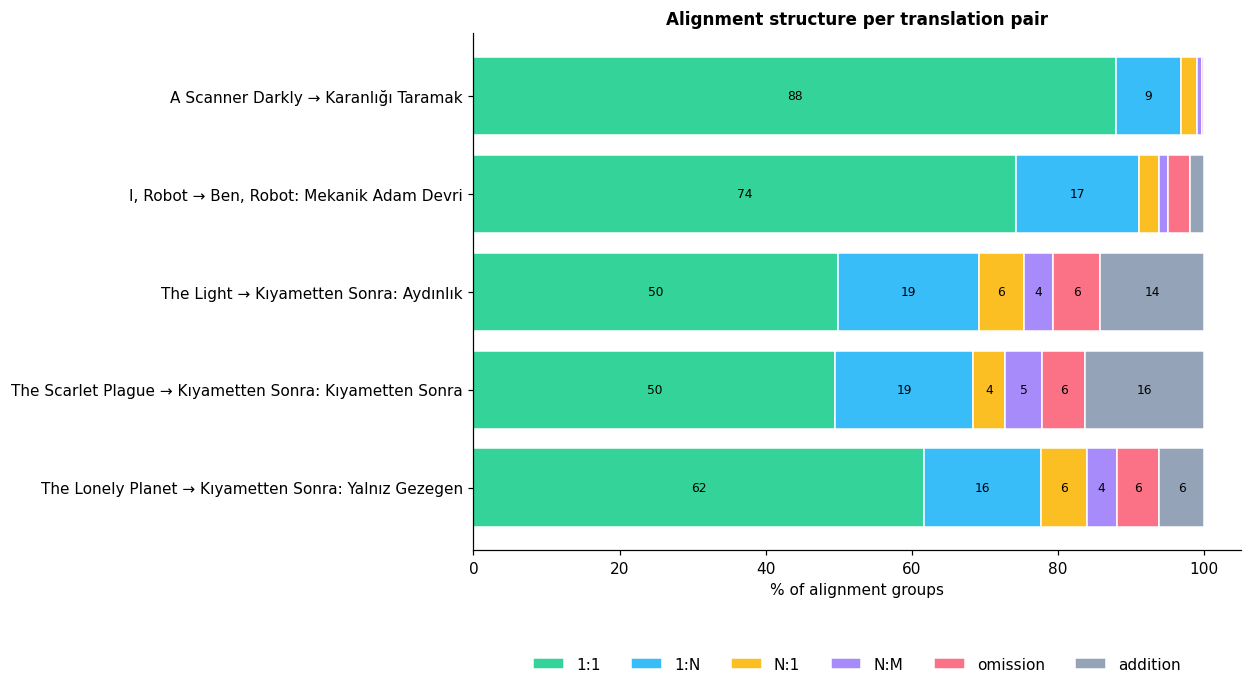

In [61]:
# Kapsamlı bir ampirik araştırma raporu oluşturma
rep = reporter.CorpusReporter(loader.config, loader.registry, run_name="not_defteri_ornek")
rep.note(field="lem", function_words="filtered", span="sentence-clamped")

# Tümce Hizalama Bölümü
rep.add_section("Tümce Hizalama Yapısı", "5 paralel çeviri çiftinde iki dilli tümce eşleşme dağılımları.")
rep.add_table("alignment_summary", summary.round(3), caption="Tümce hizalama sayıları ve oranları.")
rep.add_figure("alignment_stacked", viz.alignment_stacked(summary), caption="Şekil 1: Hizalama kategorisi oranları.")
rep.add_summary(reporter.top_bottom_summary(summary, "R_sent", "pair"))

# Sözcüksel Çeşitlilik Bölümü
rep.add_section("Sözcüksel Çeşitlilik Çözümlemesi", "Türkçe metinlerde 14 LancsBox-X metriği değerlendirmesi.")
rep.add_table("diversity_raw", div_raw.round(3), caption="Türkçe derlem genelinde ham çeşitlilik metrikleri.", index=True)
rep.add_summary(reporter.top_bottom_summary(div_raw.reset_index(), "MTLD", "index"))

# Raporu derleme (Markdown, TSV, PNG ve Excel dosyalarını üretir)
report_path = rep.finalize()
print("Rapor oluşturuldu:", report_path)

In [62]:
# Oluşturulan Markdown raporunun önizlemesi
content = report_path.read_text(encoding="utf-8")
print(content[:1500])

# Corpus analysis report – not_defteri_ornek
*Generated 2026-10-24 14:54:54 · corpus_toolkit v0.1.0 · schema 3*

**Analysis options**

- field: `lem`
- function_words: `filtered`
- span: `sentence-clamped`

**Texts in the focal sub-corpus**

- Özlem Kurdoğlu — Son Cephede Şafak [SCS-OK] (2000, Turkish indigenous)
- Philip K. Dick — A Scanner Darkly [ASD-PKD] (1977, English source; source author: Philip K. Dick; related to Özlem Kurdoğlu)
- Özlem Kurdoğlu — Karanlığı Taramak [KT-OK] (1998, Turkish translation)
- Selma Mine — OBİ,J.S.927 [O-SM] (1980, Turkish indigenous)
- Isaac Asimov — I, Robot [IR-IA] (1950, English source; source author: Isaac Asimov; related to Selma Mine)
- Selma Mine — Ben, Robot: Mekanik Adam Devri [BR-SM] (1983, Turkish translation)
- Zühtü Bayar — Sahte Uygarlık [SU-ZB] (1999, Turkish indigenous)
- Jack London — The Scarlet Plague [SP-JL] (1912, English source; source author: Jack London; related to Zühtü Bayar)
- Poul Anderson — The Light [TL-PA] (1957, Englis

#### Tek Satırda Standart Rapor Üretimi (Envanter, Hizalama, POS, Çeşitlilik):

Standart araştırma raporu üretildi: /home/ben/Documents/thesis/data/corpus_analysis/reports/standart_calisma_20261024_145454.md


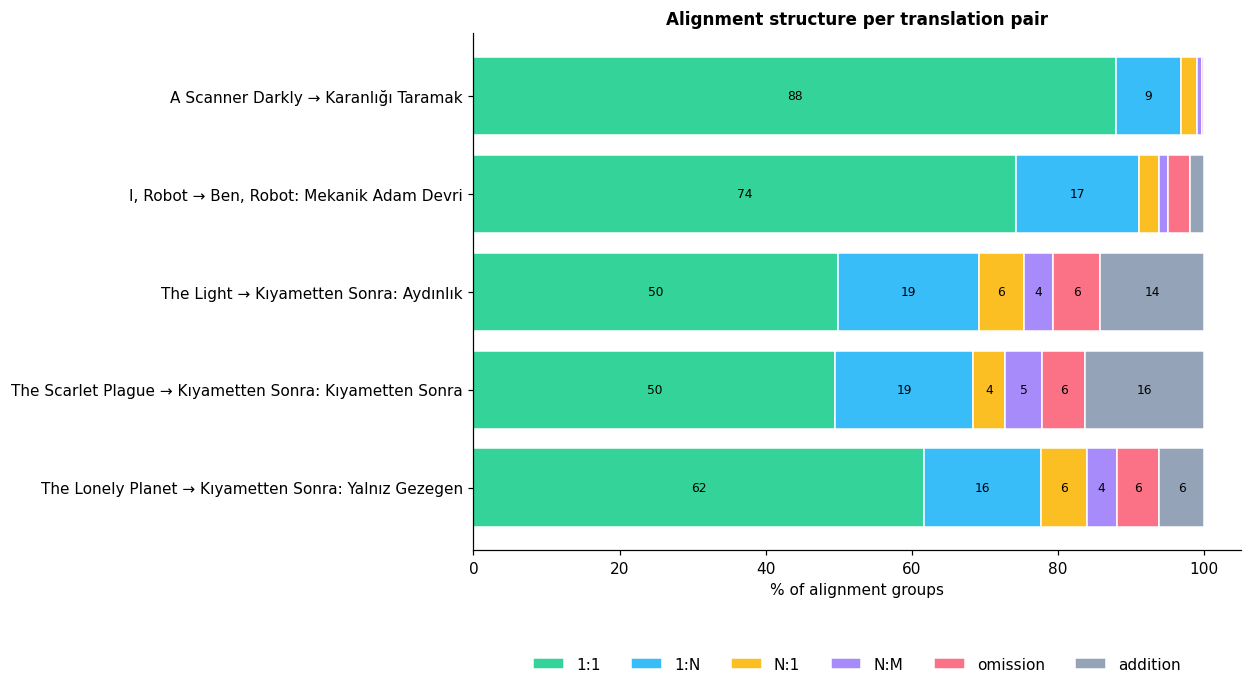

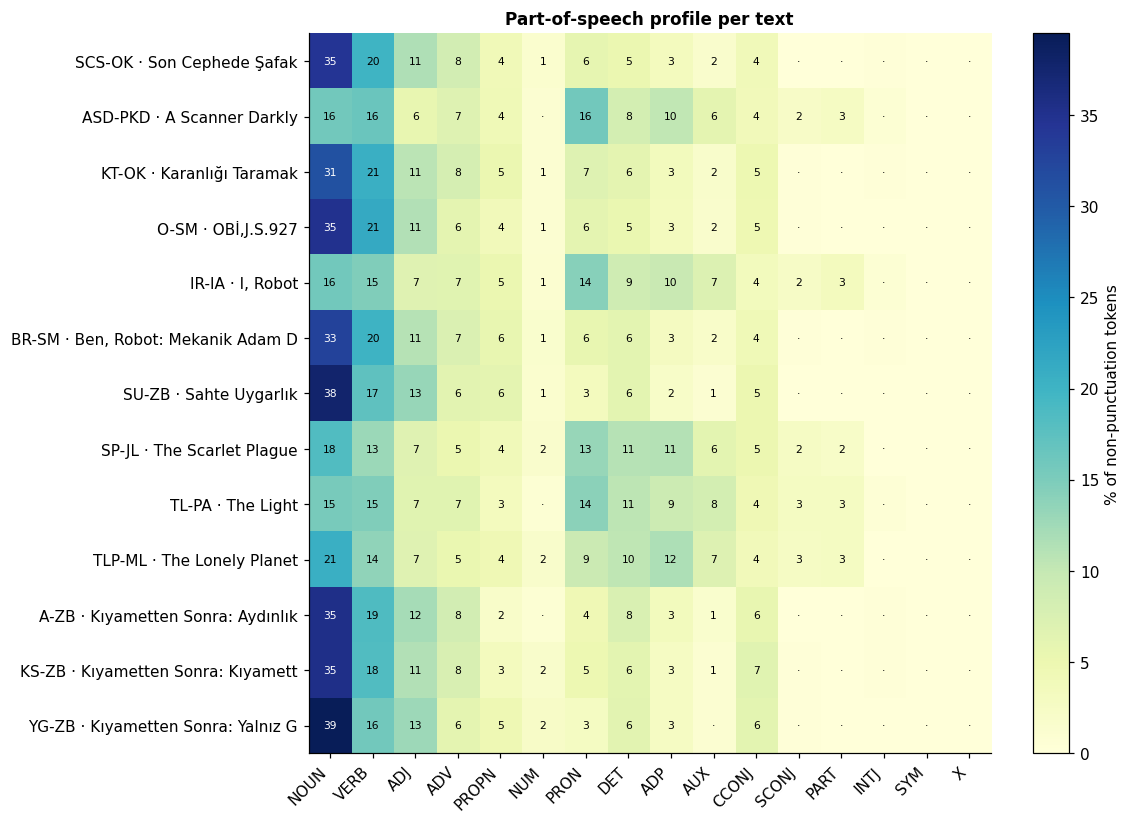

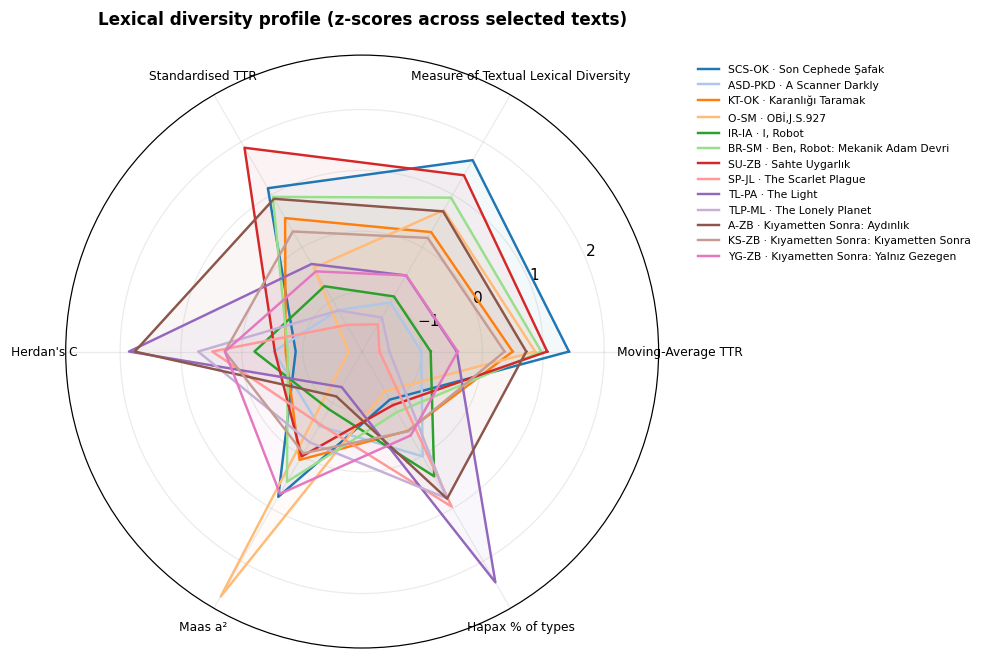

In [63]:
std_path = analysis.standard_report(loader, run_name="standart_calisma")
print("Standart araştırma raporu üretildi:", std_path)

<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Zaman damgası kullanmadan aynı çalışma adıyla rapor üretmek önceki çıktıların üzerine yazabilir: varsayılan zaman damgalamayı açık tutun.
- Excel kitapları (.xlsx) bir ofis yazılımında açıkken tekrar `finalize()` çağrısı dosya kilitleme hatası verebilir; dosyayı kapatın.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Üretilen Excel kitabındaki çalışma sayfalarının isimlerini pandas ile inceleyin.

<details><summary>Çözümü Göster</summary>

```python
import pandas as pd
xlsx_path = report_path.with_suffix('.xlsx')
print('Excel sayfalari:', pd.ExcelFile(xlsx_path).sheet_names)
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Hesaplamalı Tekrarlanabilirlik ve Denetim İzleri (Peng 2011):**
Modern dijital beşeri bilimler, ortaya konan istatistiksel iddiaların sözcükbirim ve hizalama
düzeyine kadar izlenebilir olmasını şart koşar. Ham tabloları TSV ve Excel formatlarında saklayıp
yüksek çözünürlüklü grafiklerle eşleştiren raporlama mimarimiz, tez savunması ve hakemli yayın
süreçleri için tam şeffaflık sağlar.

</div>

---
# Bölüm 13 · Etkileşimli Derlem Gezgini (GUI)
⏱ ~15 dk · 📚 Önkoşullar: Bölüm 6–10

> Derlem yorumbilimi (hermeneutics) için birleşik etkileşimli keşif aracı.

**Kazanımlar ve Öğrenme Hedefleri** — Bu bölümün sonunda şunları yapabileceksiniz:

- Arama, KWIC dizini ve eşdizimleri etkileşimli bir widget paneliyle yönetebilme
- `quick_search` işlevini betik tabanlı eşdeğer olarak kullanabilme
- Önbellekteki tabloları bilinçli olarak temizleyerek (`evict`) belleği boşaltabilme

### 13.1 Birleşik Etkileşimli Gezgin Paneli
Etkileşimli ipywidgets arayüzü, araç setinin sunduğu tüm yetenekleri tek bir dinamik grafik
arayüzde birleştirir. Paneldeki her denetim, önceki bölümlerde öğrendiğimiz işlevsel API parametrelerine
doğrudan karşılık gelir:

- **Derlem / Kategori**: Metinleri paralel çeviriler, yazar-çevirmen çiftleri ya da yerli romanlara göre filtreler.
- **Yazar-Çevirmen**: Kapsamı tek bir yazar-çevirmenle sınırlar (`Selma MİNE`, `Zühtü BAYAR`, `Özlem KURDOĞLU`).
- **Sözcükler**: Virgülle ayrılmış arama terimleri (birleşik tarama).
- **Alan**: Sözlükbirim (`lem`) veya yüzey sözcük (`tok`).
- **Eşleşme**: Tam eşleşme, joker karakter (`*`) ya da düzenli ifade (regex).
- **İşlevsel Sözcük Filtresi**: İçerik sözcüğü çözümlemesini açar/kapatır (`drop` vs `mask`).
- **Pencere Aralığı**: Öbek, tümce veya simetrik aralık ($\pm L / \pm R$).
- **Görünüm**: KWIC dizini (`kwic`, `sentence`, `table`) ya da istatistiksel `summary`.

### 📋 Komut ve İşlev Kılavuzu · Etkileşimli Gezgin Komutları

| Yöntem / İşlev | Parametreler ve Seçenekler | Örnek Kullanım |
| :--- | :--- | :--- |
| `explorer.CorpusExplorerUI(loader).show()` | Etkileşimli ipywidgets arama ve dizin panelini görüntüleme | `ui = explorer.CorpusExplorerUI(loader); ui.show()` |
| `explorer.quick_search(loader, ['sözcük'], ...)` | ConcordanceResult döndüren (kendini görüntüler; DataFrame için .to_dataframe()) betik eşdeğeri | `quick_search(loader, ['robot'], author='Selma Mine')` |
| `loader.evict_all()` | Yüklenmiş tüm metin tablolarını bellekten tahliye etme | `loader.evict_all()` |

In [64]:
# Etkileşimli widget panelini başlatma (başsız testlerde sessizce uyarı verir)
try:
    from corpus_toolkit import explorer
    ui = explorer.CorpusExplorerUI(loader)
    ui.show()
except Exception as exc:
    print("Etkileşimli arayüz başsız kipte kullanılamıyor:", exc)

### 13.2 Betik Tabanlı Eşdeğer: `quick_search`

In [65]:
# Selma Mine metinlerinde 'robot' adını arayan betik çağrısı (NDA yan yana paralel görünüm)
from corpus_toolkit.explorer import quick_search
qs_res = quick_search(loader, ["robot"], category="Author-translator related texts",
                      author="Selma Mine", field="lem", pos={"NOUN"},
                      span="phrase", view="parallel", max_lines=3)

code⇅,title⇅,language⇅,type⇅,hits⇅,running_words⇅,per10k⇅
O-SM,"OBİ,J.S.927",tr,indigenous,562,"39,695",141.580
IR-IA,"I, Robot",en,source,520,"72,429",71.794
BR-SM,"Ben, Robot: Mekanik Adam Devri",tr,translation,687,"51,632",133.057


In [66]:
# Açık bellek temizliği: Keşif sonrası tüm tabloları RAM'den tahliye etme
loader.evict_all()
print("Bellek temizlendi: Yüklenmiş tüm metin tabloları tahliye edildi.")

Bellek temizlendi: Yüklenmiş tüm metin tabloları tahliye edildi.


<div class="learn" style="border-left:4px solid #f59e0b;background:#fffbeb;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**⚠️ Sık Yapılan Hatalar ve Dikkat Edilmesi Gerekenler**

- Etkileşimli grafik arayüz, `ipywidgets` kütüphanesinin etkin olduğu canlı bir Jupyter ortamı gerektirir.
- Gezginde art arda birçok metni açmak RAM kullanımını artırabilir: uzun oturumlar arasında `loader.evict_all()` çağrısı yapın.

</div>

### ✏️ Kendini Sınama Alıştırmaları (Önce kendiniz deneyin, sonra çözümü açın)
**1.** Tüm Türkçe çeviri metinlerinde `uzay` sözlükbirimi için hızlı arama yapın ve ilk 5 bulguyu listeleyin.

<details><summary>Çözümü Göster</summary>

```python
from corpus_toolkit.explorer import quick_search
res = quick_search(loader, ['uzay'], category='Turkish translations', field='lem', view='kwic', max_lines=5)
```

</details>


<div class="scholarly" style="border-left:4px solid #3b82f6;background:#eff6ff;padding:8px 12px;border-radius:0 8px 8px 0;margin:12px 0;">

**🎓 Kuramsal Çerçeve ve Akademik Not (Çeviribilim & Derlem Dilbilim)**

**Keşifsel Veri Çözümlemesi ve Yorumbilimsel Soruşturma (Tukey 1977; Rockwell & Sinclair 2016):**
Dijital edebiyat araştırmalarında bilgisayar destekli okuma, yakın okumanın (close reading)
yerini almaz; makro düzeydeki uzaktan okuma (distant reading) ile mikro düzeydeki metinsel
derinlemesine okuma arasında diyalektik bir köprü kurar (*Hermeneutica*).

</div>

---
## 📚 Kaynakça
- Baker, M. (1993). Corpus linguistics and translation studies: Implications and applications. M. Baker, G. Francis, & E. Tognini-Bonelli (Ed.), *Text and Technology: In Honour of John Sinclair* (ss. 233–250). John Benjamins.
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological)*, 57(1), 289–300.
- Biber, D. (1988). *Variation across speech and writing*. Cambridge University Press.
- Bourdieu, P. (1993). *The Field of Cultural Production: Essays on Art and Literature*. Columbia University Press.
- Brezina, V., McEnery, T., & Wattam, S. (2015). Collocations in context: A new perspective on collocation networks. *International Journal of Corpus Linguistics*, 20(2), 139–173.
- Brezina, V., Weill-Tessier, P., & McEnery, T. (2021). *#LancsBox v. 6.0* [Bilgisayar yazılımı]. Lancaster University.
- Church, K. W., & Hanks, P. (1990). Word association norms, mutual information, and lexicography. *Computational Linguistics*, 16(1), 22–29.
- Church, K. W., Gale, W., Hanks, P., & Hindle, D. (1991). Using statistics in lexical analysis. U. Zernik (Ed.), *Lexical Acquisition: Exploiting On-Line Resources to Build a Lexicon* (ss. 115–164). Lawrence Erlbaum.
- Covington, M. A., & McFall, J. D. (2010). Cutting the Gordian knot: The Moving-Average Type–Token Ratio (MATTR). *Journal of Quantitative Linguistics*, 17(2), 94–100.
- Daille, B. (1994). *Approche mixte pour l'extraction de terminologie: statistique et linguistique* [Doktora tezi, Université Paris 7].
- Dugast, D. (1979). *Vocabulaire et stylistique: II. Les indices de richesse lexicale et leurs applications*. Slatkine.
- Dunning, T. (1993). Accurate methods for the statistics of surprise and coincidence. *Computational Linguistics*, 19(1), 61–74.
- Even-Zohar, I. (1990). Polysystem studies. *Poetics Today*, 11(1), 1–268.
- Firth, J. R. (1957). A synopsis of linguistic theory, 1930–1955. *Studies in Linguistic Analysis* (ss. 1–32). Philological Society.
- Gries, S. T. (2008). Dispersions and adjusted frequencies in corpora. *International Journal of Corpus Linguistics*, 13(4), 403–437.
- Guiraud, P. (1954). *Les caractères statistiques du vocabulaire*. Presses Universitaires de France.
- Herdan, G. (1960). *Type-token mathematics: A textbook of mathematical linguistics*. Mouton.
- Honoré, A. (1979). Some simple measures of richness of vocabulary. *ALLC Bulletin*, 7(2), 172–177.
- Juilland, A., & Chang-Rodríguez, E. (1964). *Frequency dictionary of Spanish words*. Mouton.
- Luhn, H. P. (1960). Key word-in-context index for technical literature (KWIC index). *American Documentation*, 11(4), 288–295.
- Maas, H. D. (1972). Über den Zusammenhang zwischen Wortschatzumfang und Länge eines Textes. *Zeitschrift für Literaturwissenschaft und Linguistik*, 2(8), 73–96.
- McCarthy, P. M., & Jarvis, S. (2010). MTLD, vocd-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, 42(2), 381–392.
- Nivre, J., vd. (2016). Universal Dependencies v1: A multilingual treebank collection. *Proceedings of LREC 2016*, 1659–1666.
- Peng, R. D. (2011). Reproducible research in computational science. *Science*, 334(6060), 1226–1227.
- Rockwell, G., & Sinclair, S. (2016). *Hermeneutica: Computer-assisted interpretation in the humanities*. MIT Press.
- Rychlý, P. (2008). A lexicographer-friendly association score. *Proceedings of Recent Advances in Slavonic Natural Language Processing (RASLAN 2008)*, 6–9.
- Simeoni, D. (1998). The pivotal status of the translator's habitus. *Target: International Journal of Translation Studies*, 10(1), 1–39.
- Simpson, E. H. (1949). Measurement of diversity. *Nature*, 163, 688.
- Sinclair, J. (1991). *Corpus, Concordance, Collocation*. Oxford University Press.
- Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. *Journal of Documentation*, 28(1), 11–21.
- Suvin, D. (1979). *Metamorphoses of Science Fiction: On the Poetics and History of a Literary Genre*. Yale University Press.
- Toury, G. (2012). *Descriptive Translation Studies – and beyond* (2. bs.). John Benjamins.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- Yule, G. U. (1944). *The Statistical Study of Literary Vocabulary*. Cambridge University Press.

<sub>*Tüm alıntılar doktora tezi araştırma doğruluk tablosunda (`chapter_count_truth_table.tsv`) kayıtlıdır.*</sub>